In [1]:
.libPaths("~/R/x86_64-pc-linux-gnu-library/4.4/")

library(Seurat)
library(SeuratDisk)
library(patchwork)
library(harmony)
library(reshape2)
library(RColorBrewer)
library(dplyr)
library(readr)
library(tidyverse)
library(Matrix)
library(Seurat)
library(ggplot2)
library(cowplot)
library(celldex)
library(SingleR)
library(data.table)
library(scGate)
library(ggpubr)
library(scCustomize)

ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built under R 4.5.0 but the current version is
4.5.1; it is recomended that you reinstall ‘SeuratObject’ as the ABI
for R may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Registered S3 method overwritten by 'SeuratDisk':
  method            from  
  as.sparse.H5Group Seurat

Loading required package: Rcpp


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.4     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter()

# Load data: sample1

In [3]:
sample1  <- Read10X("~/PRIMUS/data/48_seqdata/250716_Niederlova_CD4_CTL_Boston/Sample1_GEX/raw_feature_bc_matrix/")

In [4]:
sample1  <- CreateSeuratObject(sample1, min.cells = 3, min.features = 200)

In [5]:
sample1 <- NormalizeData(object = sample1)
  sample1 <- ScaleData(sample1, verbose = FALSE)
  sample1 <- FindVariableFeatures(sample1, selection.method = "vst", nfeatures = 1000, 
                                       verbose = FALSE)
  sample1 <- RunPCA(sample1, npcs = 20, verbose = FALSE)
  sample1 <- RunUMAP(sample1, reduction = "pca", dims = 1:20)
  sample1 <- FindNeighbors(sample1, dims = 1:20)
  sample1 <- FindClusters(sample1, resolution = 0.9)

Normalizing layer: counts

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
15:16:45 UMAP embedding parameters a = 0.9922 b = 1.112

15:16:45 Read 2994 rows and found 20 numeric columns

15:16:45 Using Annoy for neighbor search, n_neighbors = 30

15:16:45 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:16:46 Writing NN index file to temp file /home/vercanie/R/tmp//RtmpbToa4I/file2a24ea37509739

15:16:46 Searching Annoy index using 1 thread, search_k = 3000

15:16:47 Annoy recall = 100%

15:16:48 Commencing smooth kNN distance calibra

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2994
Number of edges: 125609

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7767
Number of communities: 9
Elapsed time: 0 seconds


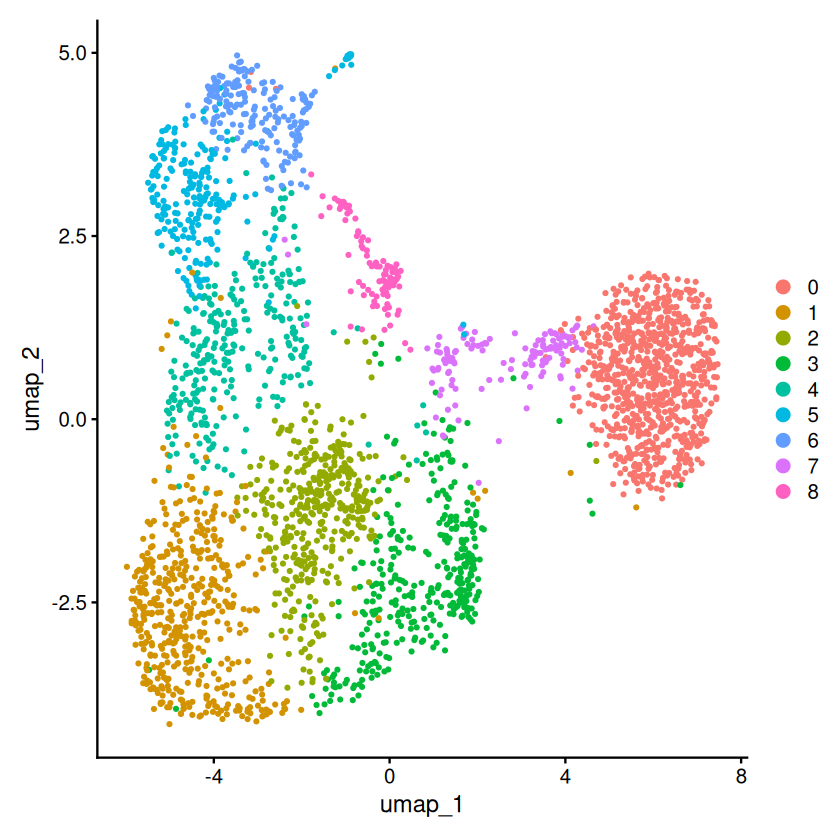

In [6]:
DimPlot(sample1)

Warning message:
“The `slot` argument of `FetchData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”


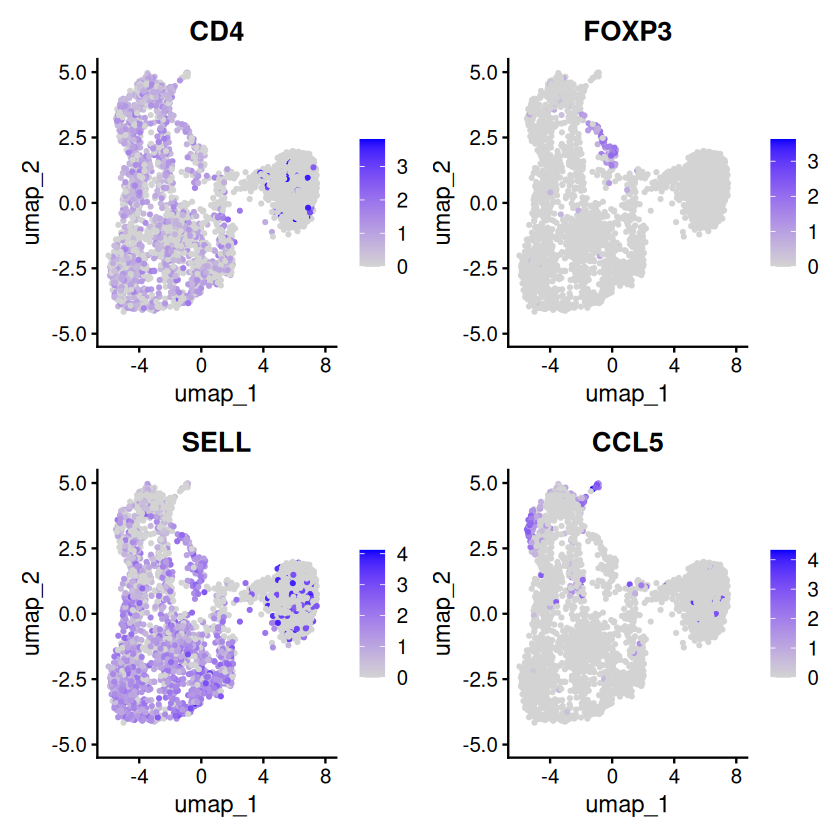

In [7]:
FeaturePlot(sample1, features = c("CD4","FOXP3","SELL","CCL5"))

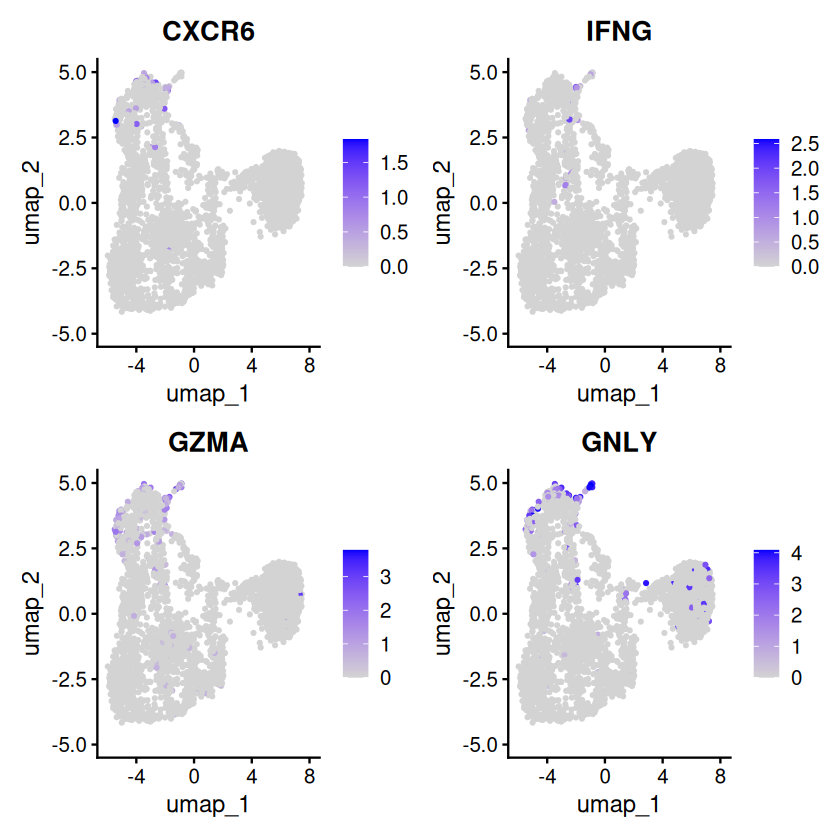

In [9]:
FeaturePlot(sample1, features = c("CXCR6","IFNG","GZMA","GNLY"))

# Load data: sample2

In [10]:
sample2  <- Read10X("~/PRIMUS/data/48_seqdata/250716_Niederlova_CD4_CTL_Boston/Sample2_GEX/filtered_feature_bc_matrix/")

In [11]:
sample2  <- CreateSeuratObject(sample2, min.cells = 3, min.features = 200)

In [12]:
sample2 <- NormalizeData(object = sample2)
  sample2 <- ScaleData(sample2, verbose = FALSE)
  sample2 <- FindVariableFeatures(sample2, selection.method = "vst", nfeatures = 1000, 
                                       verbose = FALSE)
  sample2 <- RunPCA(sample2, npcs = 20, verbose = FALSE)
  sample2 <- RunUMAP(sample2, reduction = "pca", dims = 1:20)
  sample2 <- FindNeighbors(sample2, dims = 1:20)
  sample2 <- FindClusters(sample2, resolution = 0.9)

Normalizing layer: counts

15:19:38 UMAP embedding parameters a = 0.9922 b = 1.112

15:19:38 Read 708 rows and found 20 numeric columns

15:19:38 Using Annoy for neighbor search, n_neighbors = 30

15:19:38 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:19:38 Writing NN index file to temp file /home/vercanie/R/tmp//RtmpbToa4I/file2a24ea4b1e3af0

15:19:38 Searching Annoy index using 1 thread, search_k = 3000

15:19:39 Annoy recall = 100%

15:19:40 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:19:43 Initializing from normalized Laplacian + noise (using RSpectra)

15:19:43 Commencing optimization for 500 epochs, with 26340 positive edges

15:19:43 Using rng type: pcg

15:19:45 Optimization finished

Computing nearest neighb

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 708
Number of edges: 28162

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6150
Number of communities: 6
Elapsed time: 0 seconds


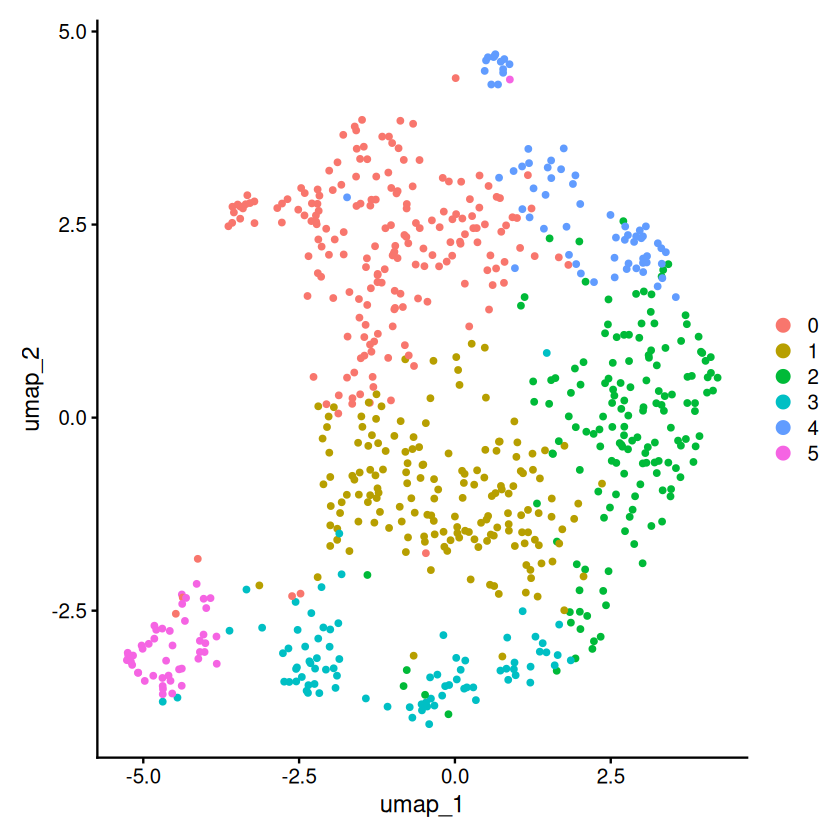

In [13]:
DimPlot(sample2)

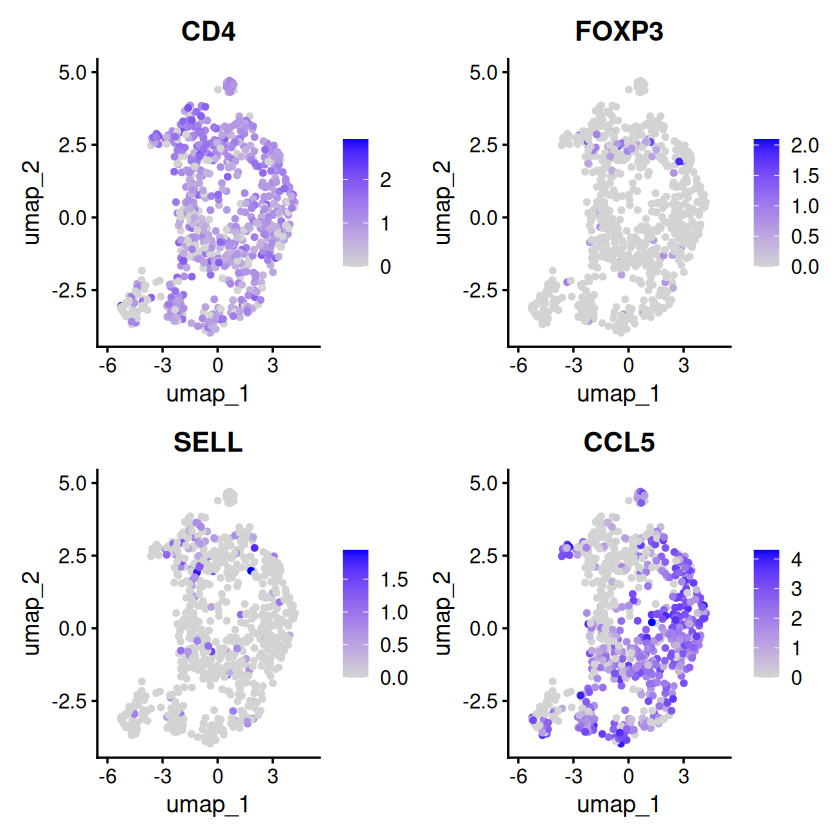

In [14]:
FeaturePlot(sample2, features = c("CD4","FOXP3","SELL","CCL5"))

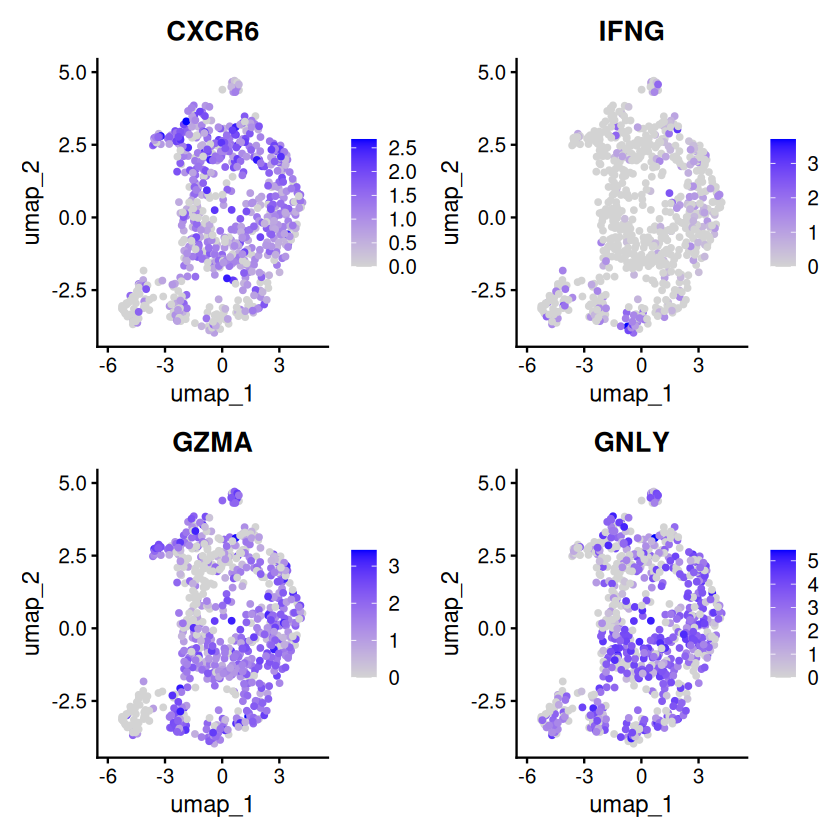

In [15]:
FeaturePlot(sample2, features = c("CXCR6","IFNG","GZMA","GNLY"))

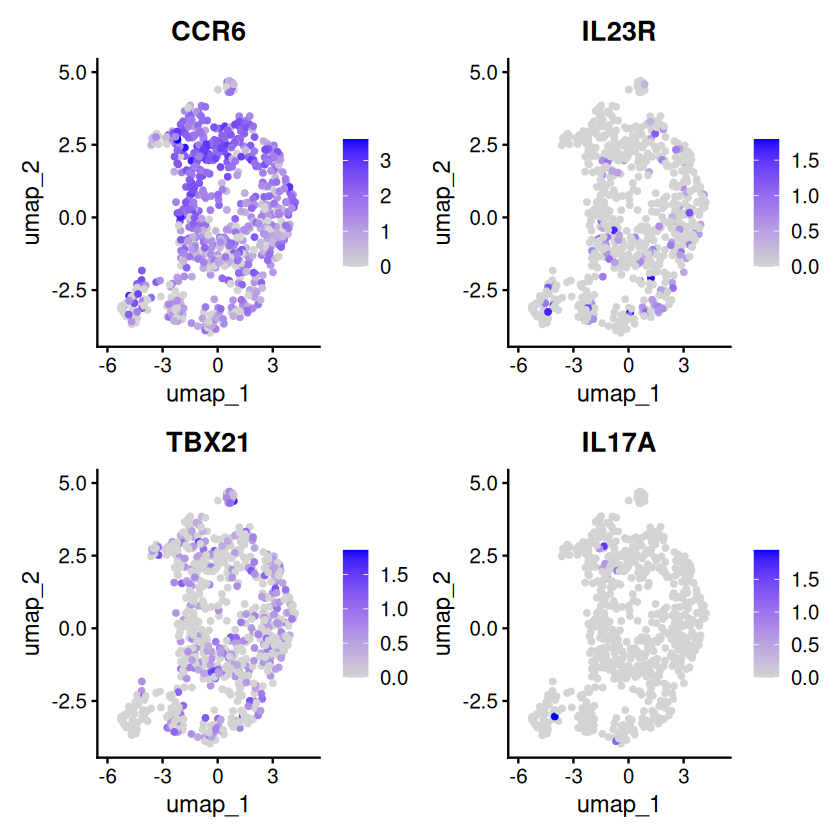

In [16]:
FeaturePlot(sample2, features = c("CCR6","IL23R","TBX21","IL17A"))

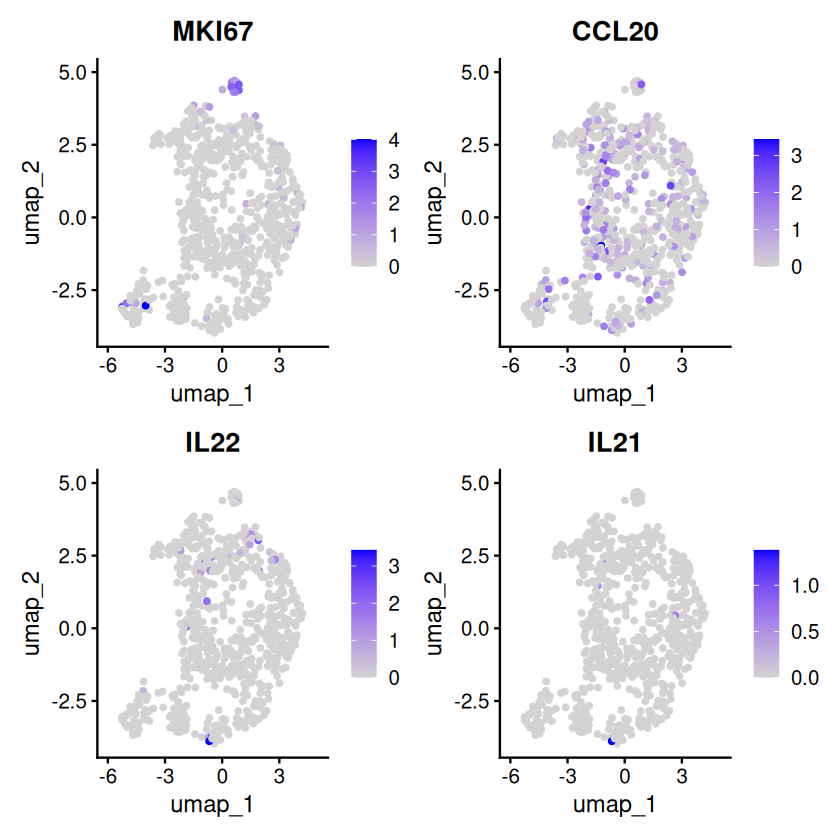

In [18]:
FeaturePlot(sample2, features = c("MKI67","CCL20","IL22","IL21"))

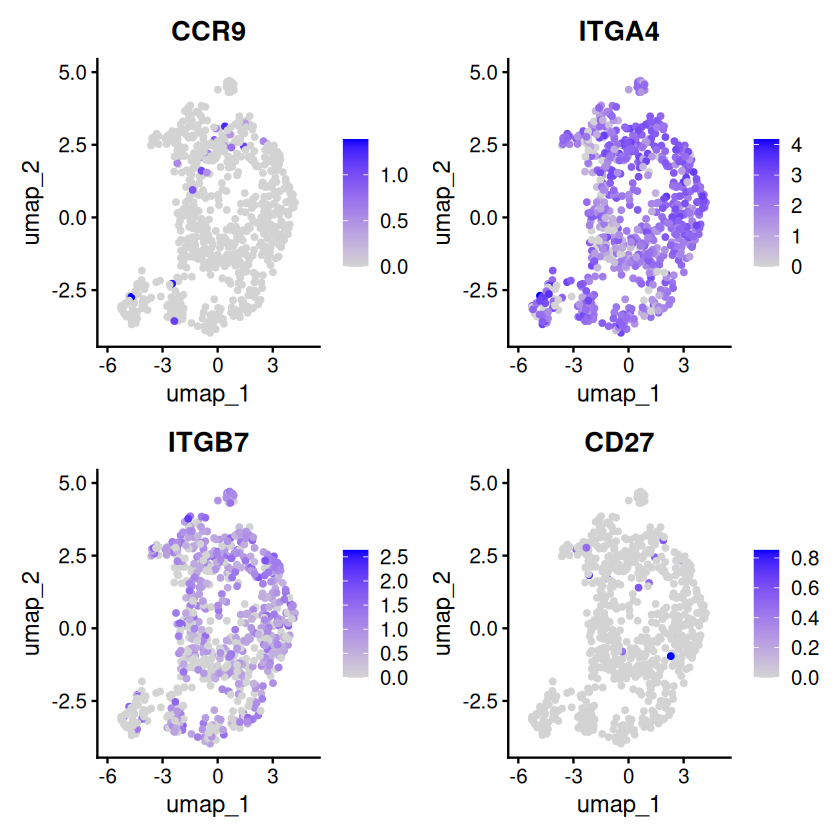

In [20]:
FeaturePlot(sample2, features = c("CCR9","ITGA4","ITGB7","CD27"))

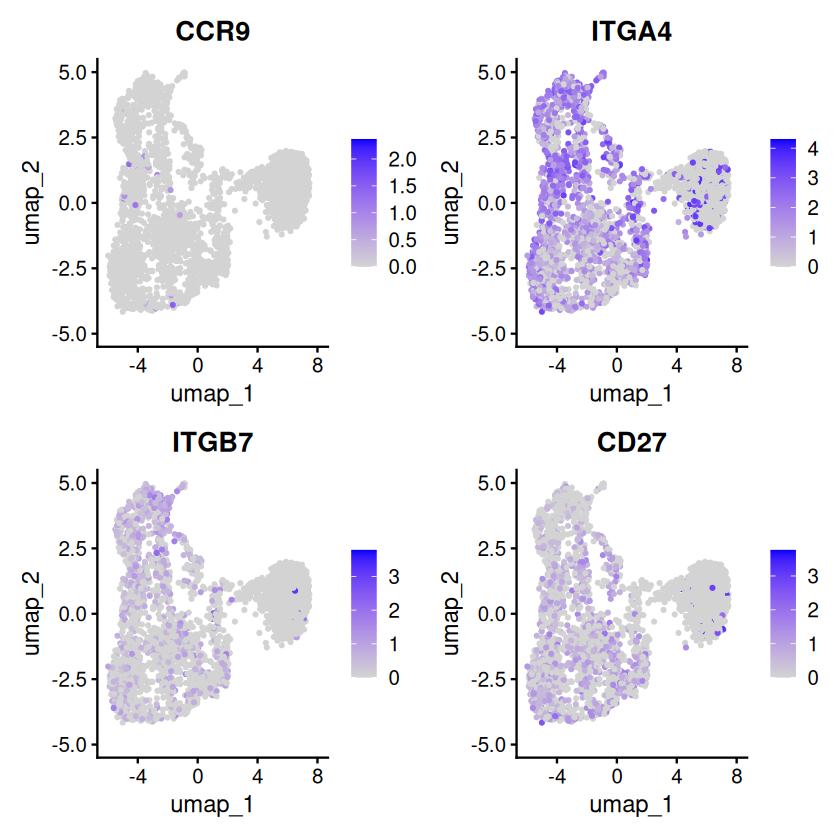

In [21]:
FeaturePlot(sample1, features = c("CCR9","ITGA4","ITGB7","CD27"))

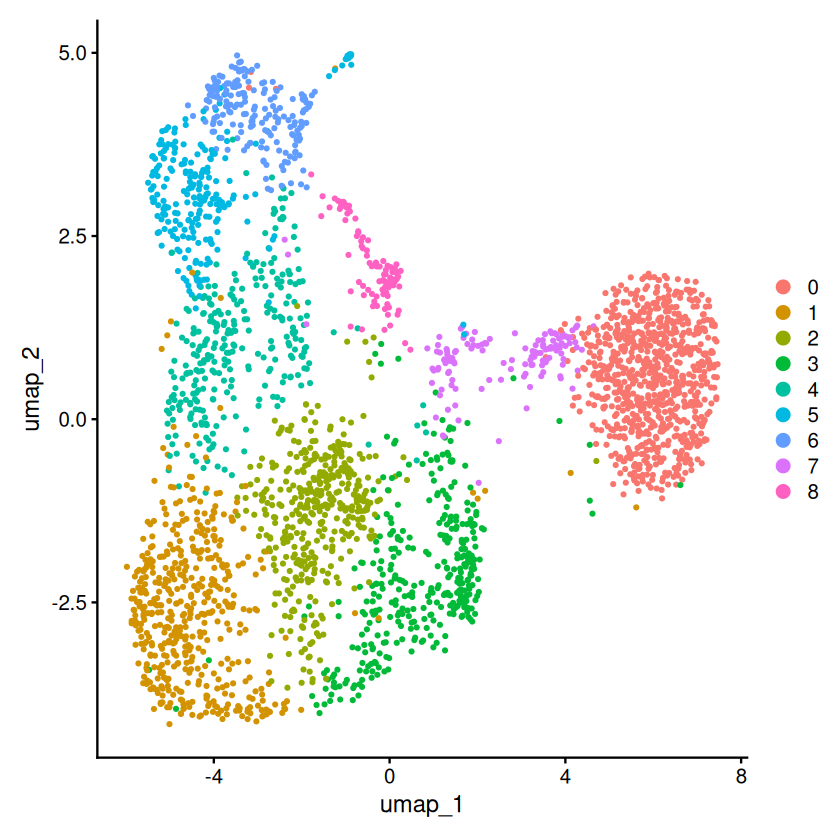

In [23]:
DimPlot(sample1)

# QC - remove low quality clusters

Warning message:
“`PackageCheck()` was deprecated in SeuratObject 5.0.0.
ℹ Please use `rlang::check_installed()` instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”


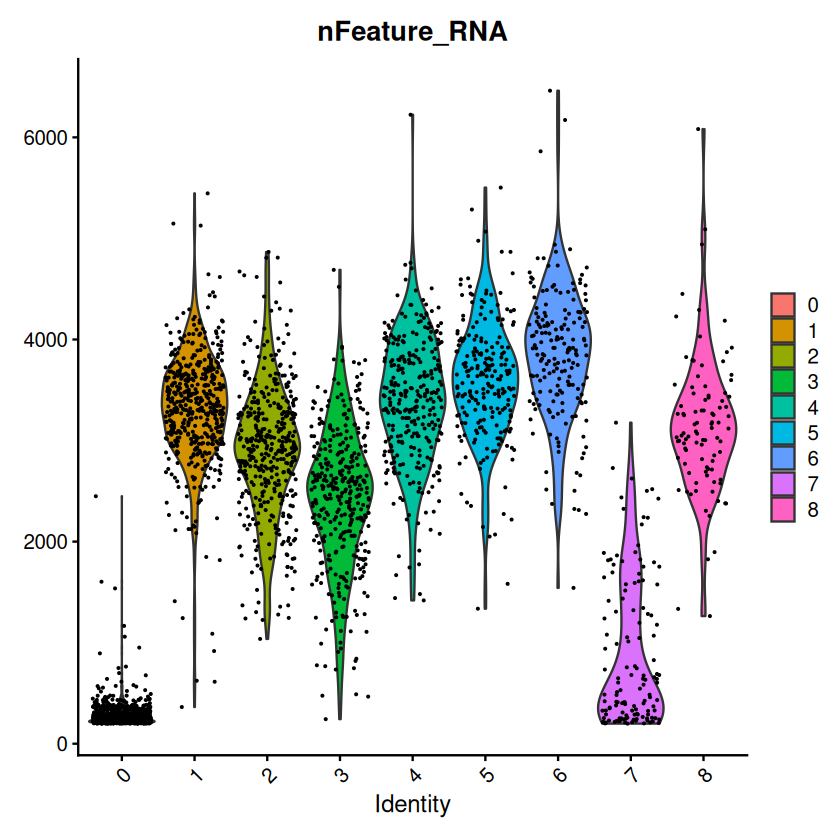

In [25]:
VlnPlot(sample1, features = "nFeature_RNA")

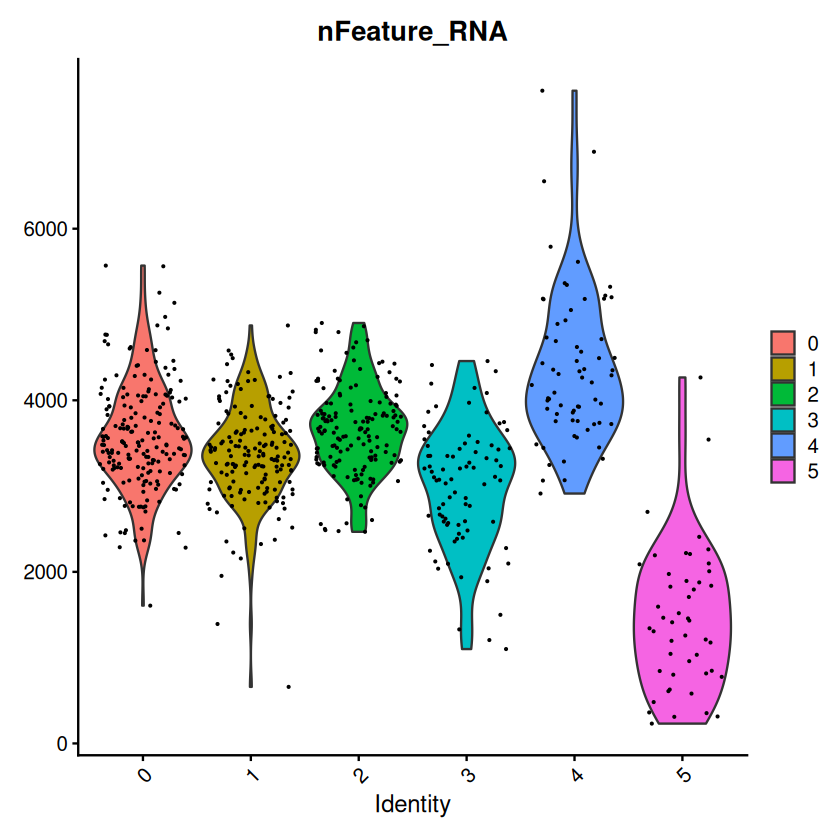

In [26]:
VlnPlot(sample2, features = "nFeature_RNA")

In [27]:
sample1_filt  <- subset(sample1, seurat_clusters %in% c(1:6,8))
sample2_filt  <- subset(sample2, seurat_clusters %in% c(1:4))


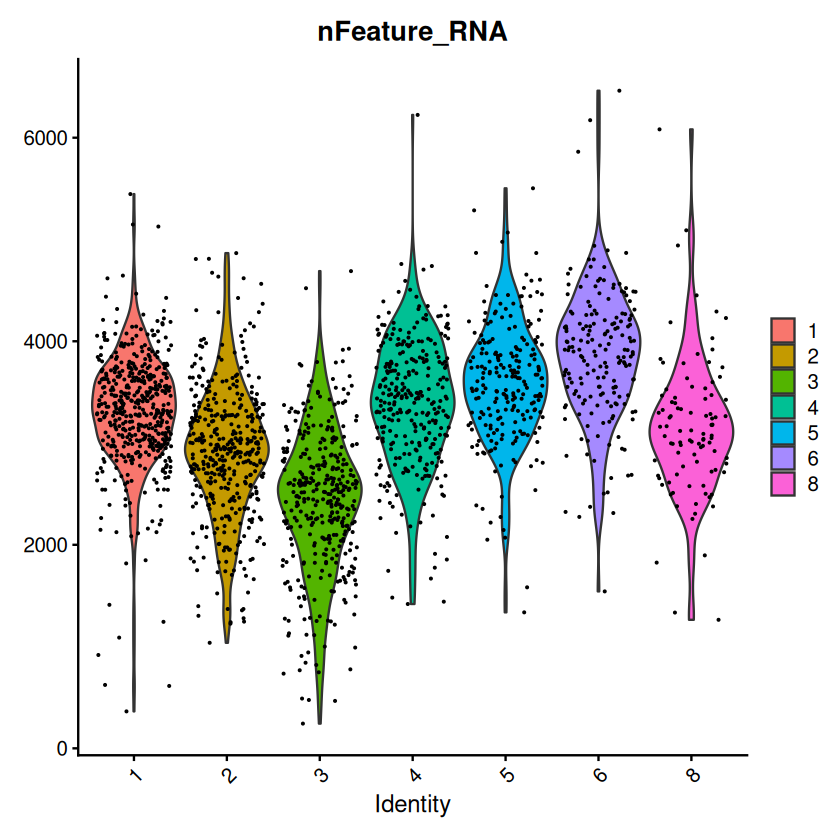

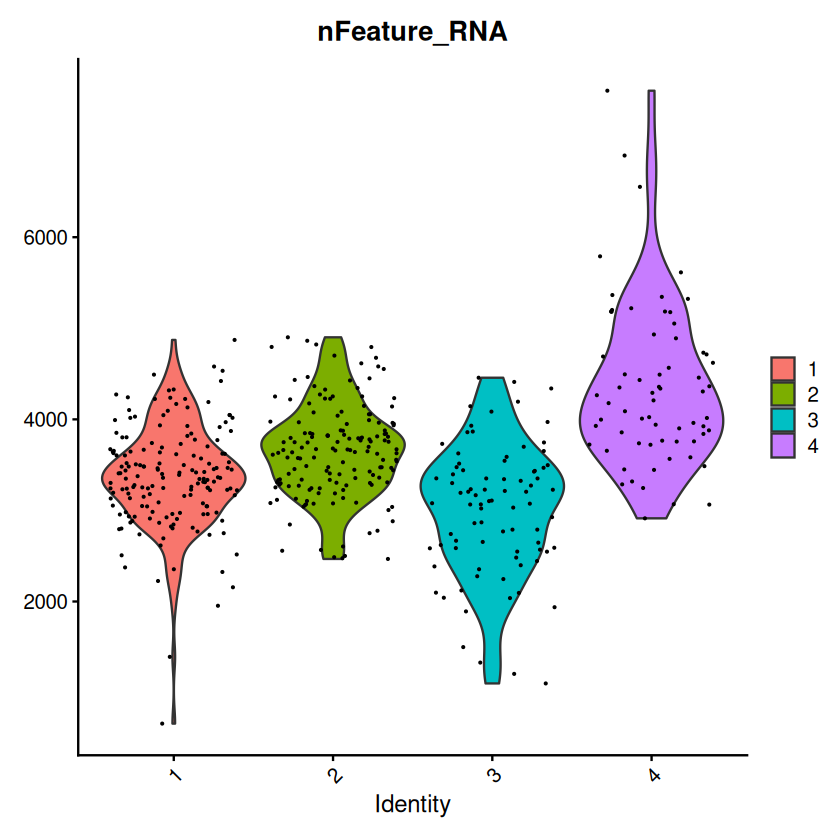

In [28]:
VlnPlot(sample1_filt, features = "nFeature_RNA")
VlnPlot(sample2_filt, features = "nFeature_RNA")

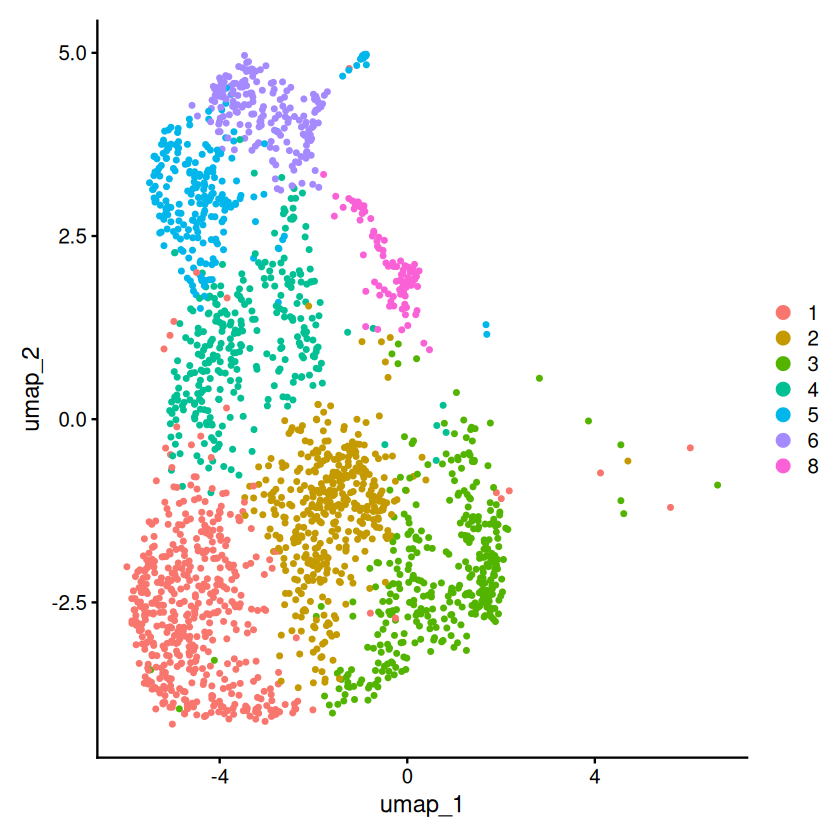

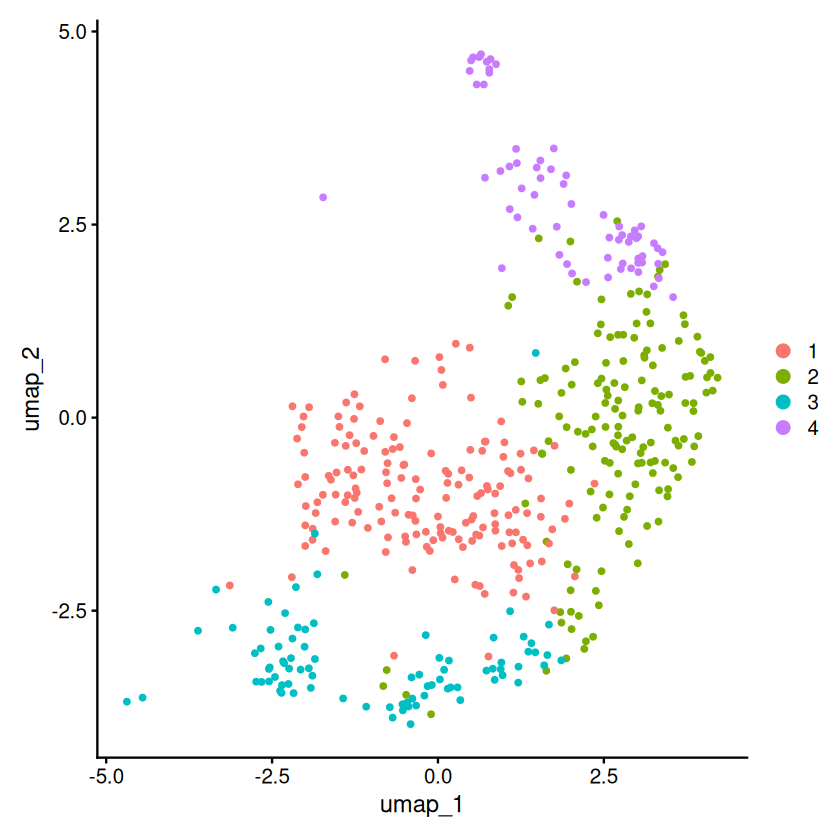

In [29]:
DimPlot(sample1_filt)
DimPlot(sample2_filt)

In [30]:
sample1_filt <- NormalizeData(object = sample1_filt)
  sample1_filt <- ScaleData(sample1_filt, verbose = FALSE)
  sample1_filt <- FindVariableFeatures(sample1_filt, selection.method = "vst", nfeatures = 1000, 
                                       verbose = FALSE)
  sample1_filt <- RunPCA(sample1_filt, npcs = 12, verbose = FALSE)
  sample1_filt <- RunUMAP(sample1_filt, reduction = "pca", dims = 1:12)
  sample1_filt <- FindNeighbors(sample1_filt, dims = 1:12)
  sample1_filt <- FindClusters(sample1_filt, resolution = 0.5)

Normalizing layer: counts

Warning message:
“Different features in new layer data than already exists for scale.data”
Warning message in PrepDR5(object = object, features = features, layer = layer, :
“The following features were not available: ENSG00000289901, TMSB4X, B2M, LINC-PINT, LTB, PLCL1, TNFAIP3, EEF1A1, DNAJC1, NAMPT, FGF14, LPCAT2, MAML2, SVIL, CD99, GPRIN3, SIK2, PCSK5, ATP10A, STAT4, SOS1, FAM177A1, ICOS, LYAR, CHKA, ARID5B, HSPA8, GTDC1, FAM241A, CAMK1D, NEDD9, PRKN, DEAF1, CRY1, BTBD9, OSBPL1A, RALGAPA1, CCND1, PNP, LINC01619, GPR183, FOSB, ITGB5, TICRR, KRTAP12-3, YES1, CEP83, ENSG00000287070, SAT1, HSP90AB1, HERC1, TTC39C, MSN.”
Warning message:
“Number of dimensions changing from 20 to 12”
09:31:04 UMAP embedding parameters a = 0.9922 b = 1.112

09:31:04 Read 2054 rows and found 12 numeric columns

09:31:04 Using Annoy for neighbor search, n_neighbors = 30

09:31:04 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2054
Number of edges: 71808

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8360
Number of communities: 7
Elapsed time: 0 seconds


In [31]:
sample2_filt <- NormalizeData(object = sample2_filt)
  sample2_filt <- ScaleData(sample2_filt, verbose = FALSE)
  sample2_filt <- FindVariableFeatures(sample2_filt, selection.method = "vst", nfeatures = 1000, 
                                       verbose = FALSE)
  sample2_filt <- RunPCA(sample2_filt, npcs = 12, verbose = FALSE)
  sample2_filt <- RunUMAP(sample2_filt, reduction = "pca", dims = 1:12)
  sample2_filt <- FindNeighbors(sample2_filt, dims = 1:12)
  sample2_filt <- FindClusters(sample2_filt, resolution = 0.5)

Normalizing layer: counts

Warning message:
“Different features in new layer data than already exists for scale.data”
Warning message in PrepDR5(object = object, features = features, layer = layer, :
“The following features were not available: KIAA1958, RAD21, ENSG00000254571, TCEAL4, ACAT2, DHRS4-AS1, ENSG00000286616, ENSG00000289957, MAP3K5, SAE1, TMEM106C, HISLA, ATP6V0D1-DT, HINT2, JUNB, ENSG00000285165, ZNF485, SH3BGRL3, CRIP1, H2BC12, CFAP44, SMC1A, ALYREF, PMEPA1, NSMCE1-DT, EFNB2, HNRNPA2B1, UBE2K, TNFSF13B, ENSG00000258526, PHF19, MPZL1, PTMA, RFWD3, RFC2, NASP, PTPN13, OSM, ARHGAP19, CDC25B, UHRF1, ENSG00000253853, ENSG00000251314, FRMD4B, GSTM1, MIR9-1HG, ENSG00000242880, BUB3, KNSTRN, NCAPD3, RPA3, PKM, MT-CO1, CALM1, EPB41L2, POLE2, PA2G4, TRIM59, MAK, LRRC1, TRBJ2-5, NAV2, OSBPL1A, PHF21A, GARS1, PMS2P4, ANP32B, XRCC5, ITGA4, ENSG00000255882, TMSB15B-AS1, LINC01393, ENSG00000288755, KBTBD6, GDAP1, ID2, VRK1, NFKBIA, NSD2, TCF19, CIITA, HPF1, MBNL1, WDR19, CCDC18, RANBP1, 

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 469
Number of edges: 16779

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.6898
Number of communities: 4
Elapsed time: 0 seconds


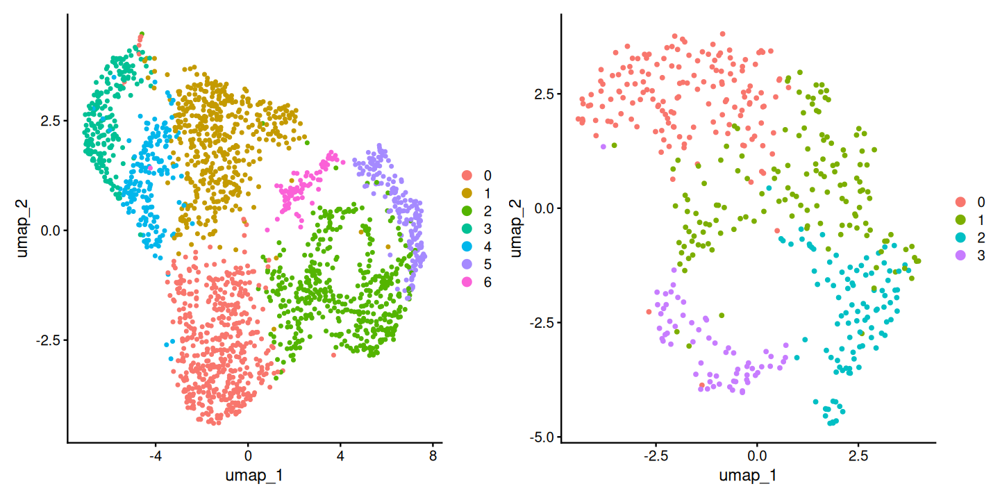

In [35]:
options(repr.plot.width = 12, repr.plot.height = 6)
DimPlot(sample1_filt) +
DimPlot(sample2_filt) +
plot_layout(ncol = 2)


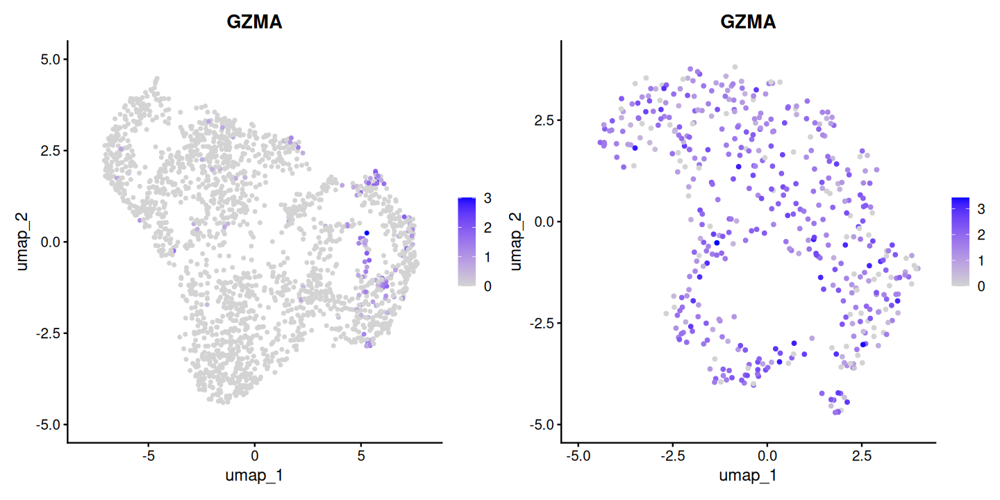

In [36]:
FeaturePlot(sample1_filt, features = c("GZMA")) +
FeaturePlot(sample2_filt, features = c("GZMA")) +
plot_layout(ncol = 2)

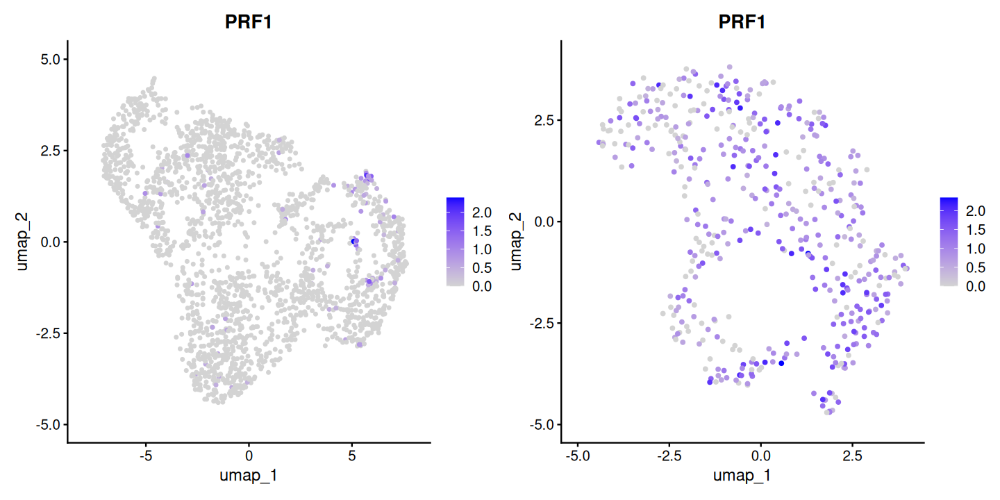

In [42]:
FeaturePlot(sample1_filt, features = c("PRF1")) +
FeaturePlot(sample2_filt, features = c("PRF1")) +
plot_layout(ncol = 2)

In [43]:
sample2_filt

An object of class Seurat 
15264 features across 469 samples within 1 assay 
Active assay: RNA (15264 features, 1000 variable features)
 3 layers present: counts, data, scale.data
 2 dimensional reductions calculated: pca, umap

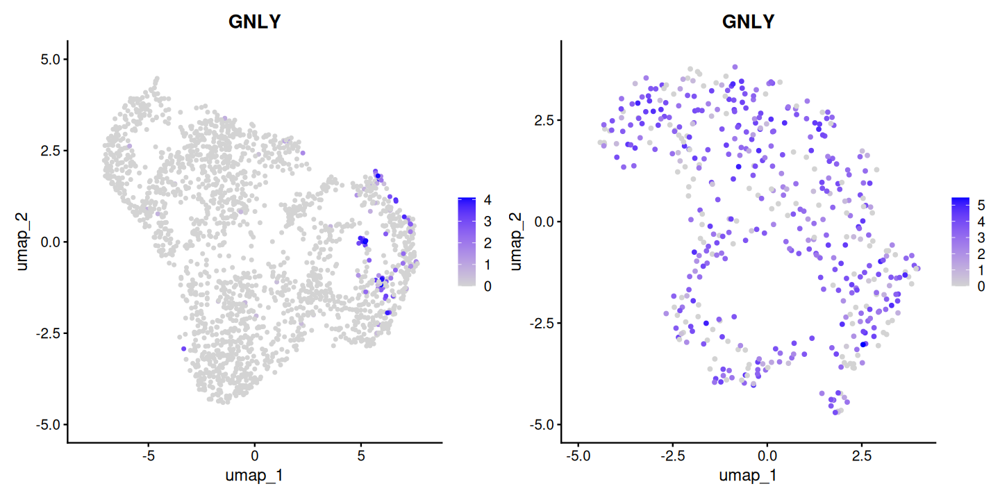

In [38]:
FeaturePlot(sample1_filt, features = c("GNLY")) +
FeaturePlot(sample2_filt, features = c("GNLY")) +
plot_layout(ncol = 2)

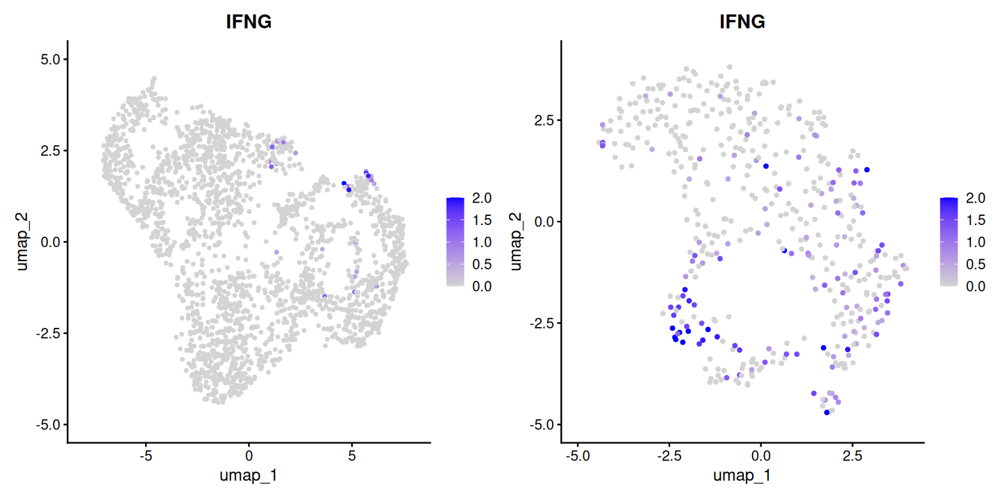

In [40]:
FeaturePlot(sample1_filt, features = c("IFNG"), max.cutoff = 2) +
FeaturePlot(sample2_filt, features = c("IFNG"), max.cutoff = 2) +
plot_layout(ncol = 2)

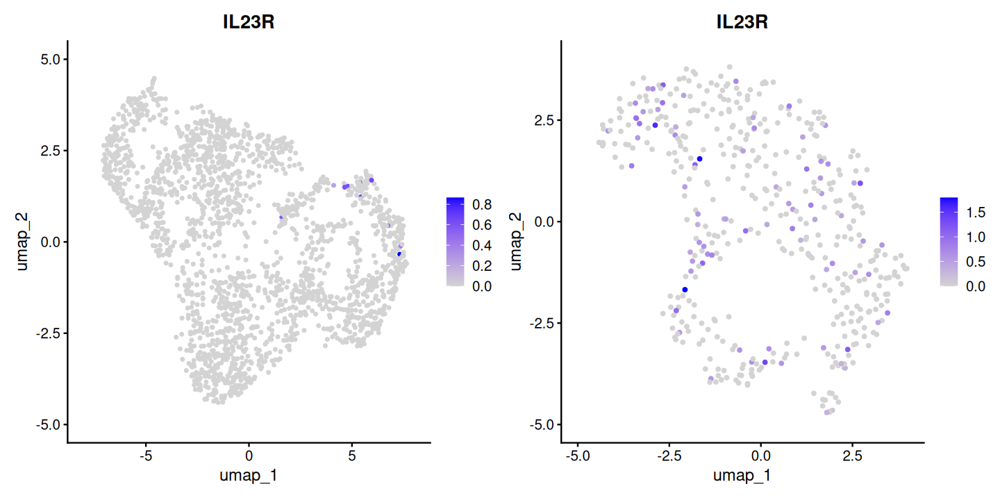

In [41]:
FeaturePlot(sample1_filt, features = c("IL23R"), max.cutoff = 2) +
FeaturePlot(sample2_filt, features = c("IL23R"), max.cutoff = 2) +
plot_layout(ncol = 2)

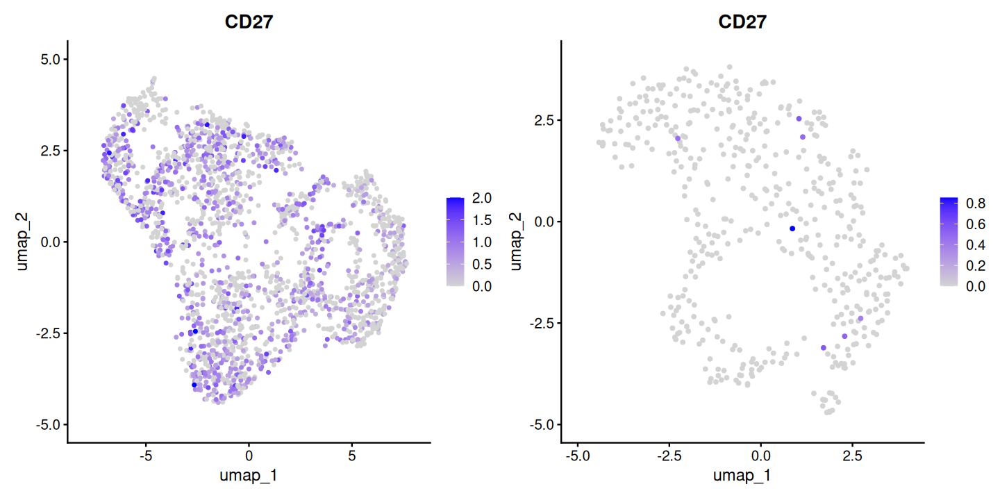

In [44]:
FeaturePlot(sample1_filt, features = c("CD27"), max.cutoff = 2) +
FeaturePlot(sample2_filt, features = c("CD27"), max.cutoff = 2) +
plot_layout(ncol = 2)

# Freemuxlet

## Sample1

In [88]:
freemux_sample1  <- data.table::fread("~/PRIMUS/home//vercanie/Software/Demuxafy/data/sample1/out/freemuxlet.clust1.samples.gz")

In [90]:
freemux_sample1$DROPLET.TYPE  %>% table

.
 AMB  DBL  SNG 
  10   14 2193 

In [91]:
freemux_sample1$BEST.GUESS  %>% table

.
0,0 1,0 1,1 2,0 2,1 2,2 3,0 3,1 3,2 3,3 4,1 4,3 4,4 
446   4 422   1   1 444   2   1   2 473   1   2 418 

In [92]:
colnames(sample1_filt) %in% freemux_sample1$BARCODE  %>% table

.
FALSE  TRUE 
    7  2047 

In [93]:
sample1_filt$barcode  <- colnames(sample1_filt)

In [94]:
md1  <- sample1_filt@meta.data  %>% left_join(freemux_sample1  %>% dplyr::select(barcode = BARCODE, Freemuxlet_ID = BEST.GUESS, 
                                                                                Freemuxlet_doublet = DROPLET.TYPE))

Joining with `by = join_by(barcode)`


In [96]:
rownames(md1)  <- colnames(sample1_filt)

In [97]:
sample1_filt@meta.data  <- md1

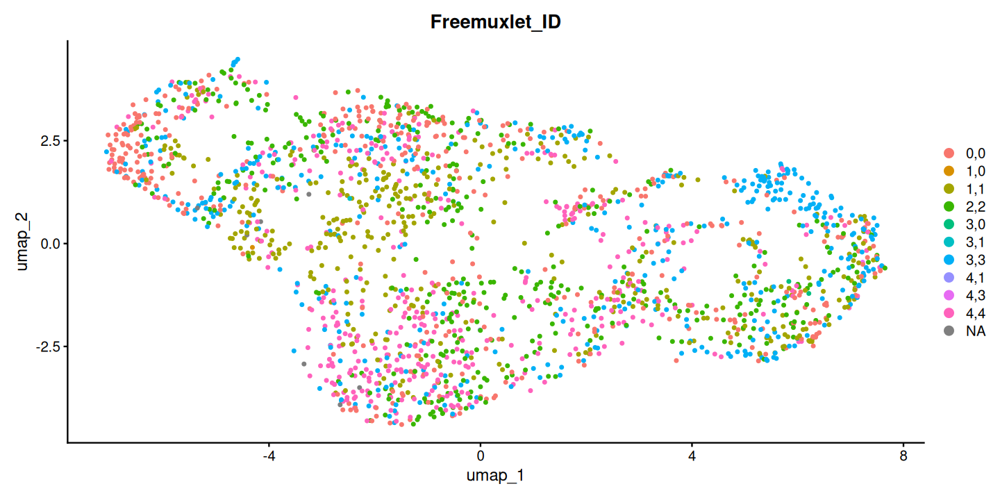

In [98]:
DimPlot(sample1_filt, group.by = "Freemuxlet_ID")

## Sample2

In [99]:
freemux_sample2  <- data.table::fread("~/PRIMUS/home//vercanie/Software/Demuxafy/data/sample2/out/freemuxlet.clust1.samples.gz")

In [100]:
freemux_sample2$DROPLET.TYPE  %>% table

.
AMB SNG 
  6 716 

In [101]:
freemux_sample2$BEST.GUESS  %>% table

.
0,0 1,1 2,2 3,3 4,4 
542  89  34  25  32 

In [102]:
colnames(sample2_filt) %in% freemux_sample2$BARCODE  %>% table

.
TRUE 
 469 

In [103]:
sample2_filt$barcode  <- colnames(sample2_filt)

In [104]:
md1  <- sample2_filt@meta.data  %>% left_join(freemux_sample2  %>% dplyr::select(barcode = BARCODE, Freemuxlet_ID = BEST.GUESS, 
                                                                                Freemuxlet_doublet = DROPLET.TYPE))

Joining with `by = join_by(barcode)`


In [105]:
rownames(md1)  <- colnames(sample2_filt)

In [106]:
sample2_filt@meta.data  <- md1

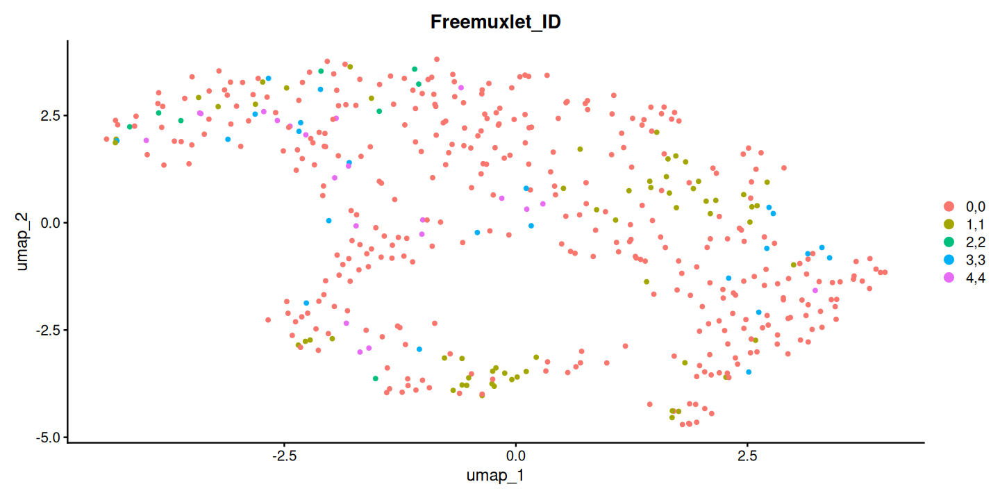

In [107]:
DimPlot(sample2_filt, group.by = "Freemuxlet_ID")

# Merge samples

In [108]:
sample1_filt$sample  <- "Sample1"
sample2_filt$sample  <- "Sample2"

sample  <- merge(sample1_filt, sample2_filt)

In [109]:
sample <- JoinLayers(sample)


In [110]:
sample <- NormalizeData(object = sample)
  sample <- ScaleData(sample, verbose = FALSE)
  sample <- FindVariableFeatures(sample, selection.method = "vst", nfeatures = 1000, 
                                       verbose = FALSE)
  sample <- RunPCA(sample, npcs = 12, verbose = FALSE)
  sample <- RunUMAP(sample, reduction = "pca", dims = 1:12)
  sample <- FindNeighbors(sample, dims = 1:12)
  sample <- FindClusters(sample, resolution = 0.5)

Normalizing layer: counts

Warning message:
“Different features in new layer data than already exists for scale.data”
Warning message in PrepDR5(object = object, features = features, layer = layer, :
“The following features were not available: TRBV25-1, TRBV4-1, TRBV11-1, PGAP1, EDA, FAM13A, TRAV41, PITPNA, TRBV10-2, PPP1R2C, LRRC7, NIBAN1, TRBV10-1, TRBV16, KRT1, ENSG00000282885, TRBV12-5, TRDC, GPR15, AREG, CDO1, ID3, TYROBP, PTPRM, RPS26, CXCR6, KCNQ5, ENSG00000271893, PRG4, NEXMIF, CST7, PRF1, GAB1, GBP5, MYO1F, TAFA2, ATP1B3, PLXNA4, YBX3, RBMS3, TNFRSF9, GK, GRIP1, ALOX5AP, IGFBP3, EMP1, ADAM23, TNFRSF19, SGK1, NEFL, SH3RF1, ADGRV1, SDK1, ENSG00000283415, KCNIP4, ENSG00000286863, ENSG00000197585, EPB41L3, SAMD4A, IL21, S100A11, CTLA4, CHN1, DST, DDIT4, C12orf75, MYO1E, SGSM3, CHAC1, ANKRD36BP2, LINC01725, CCSER1, SV2C, TAFA1, ANKRD28, HLA-DPA1, CRB1, ANXA2, LINC02315, TNFRSF11A, SGO1-AS1, ENSG00000267011, FRY, IL4I1, S100A10, HOPX, PCBP3, RFX2, LYZ, IL17A, SEMA5A, LINC02888, HES1

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2523
Number of edges: 91473

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8514
Number of communities: 7
Elapsed time: 0 seconds


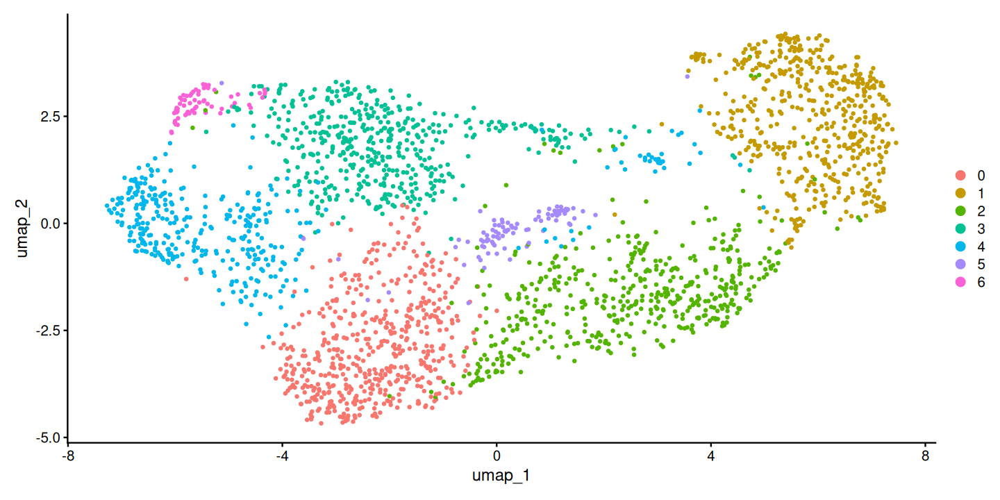

In [111]:
DimPlot(sample)

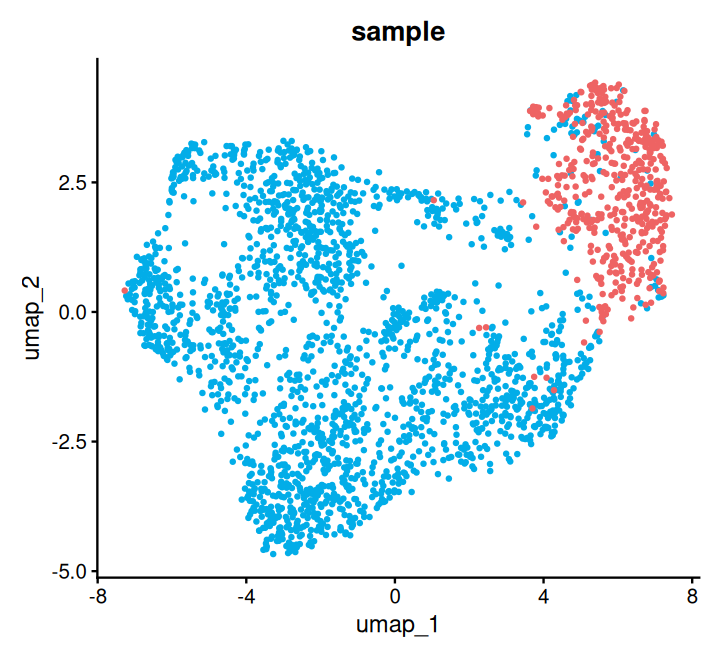

In [235]:
options(repr.plot.width = 6, repr.plot.height = 5.5)
DimPlot(sample, group.by = "sample", cols = c("#02ade8ff","indianred2")) + NoLegend()

In [ ]:
DimPlot(sample, group.by = "sample")

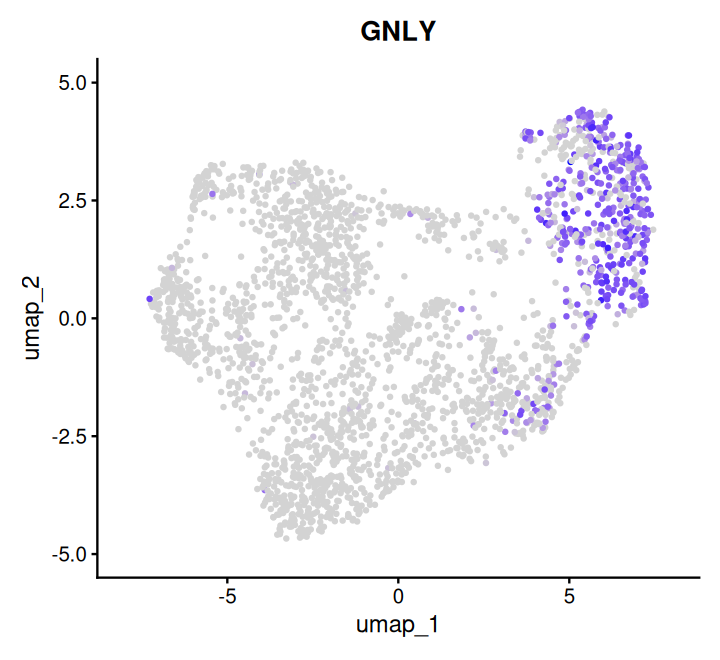

In [237]:
options(repr.plot.width = 6, repr.plot.height = 5.5)
FeaturePlot(sample, features = c("GNLY")) + NoLegend()

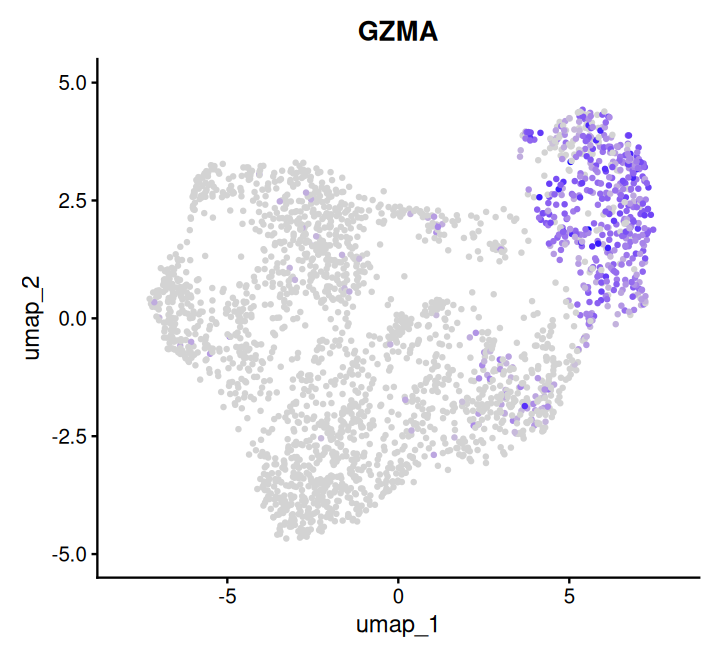

In [238]:
options(repr.plot.width = 6, repr.plot.height = 5.5)
FeaturePlot(sample, features = c("GZMA")) + NoLegend()

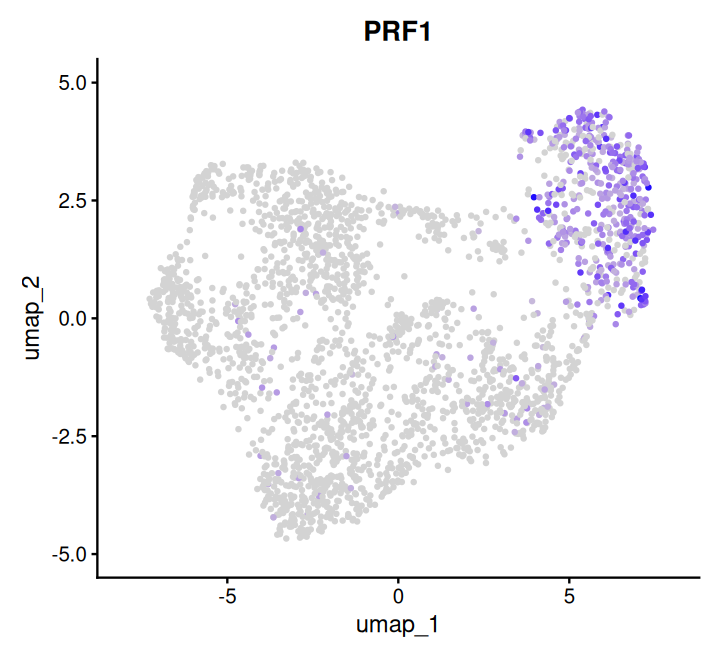

In [239]:
FeaturePlot(sample, features = c("PRF1")) + NoLegend()

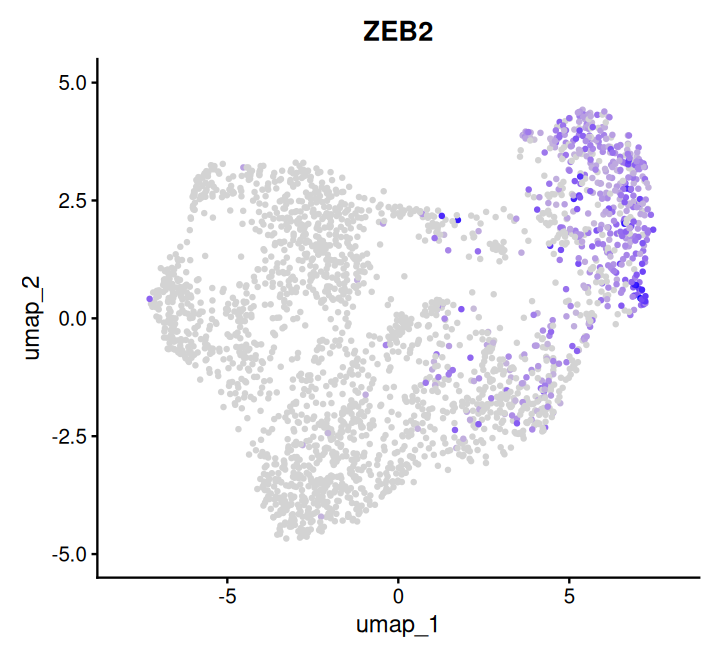

In [247]:
FeaturePlot(sample, features = c("ZEB2")) + NoLegend()

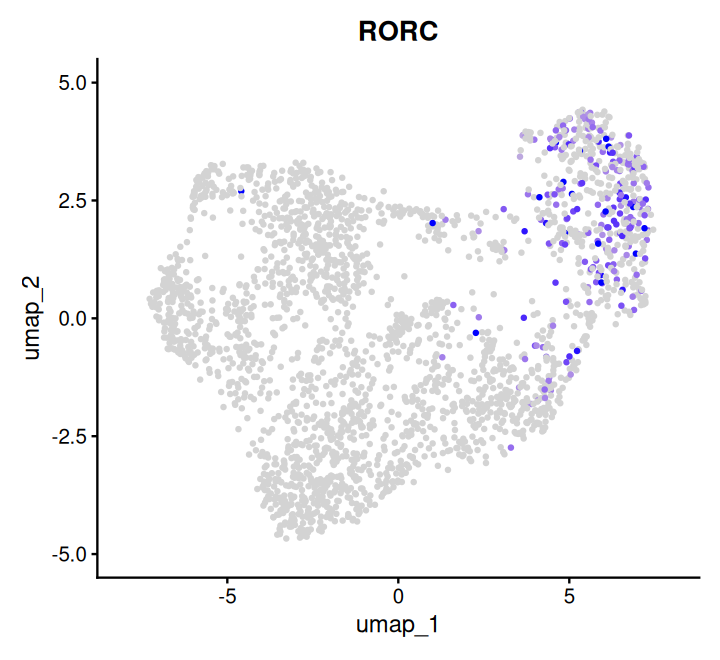

In [248]:
FeaturePlot(sample, features = c("RORC"), max.cutoff = 1) + NoLegend()

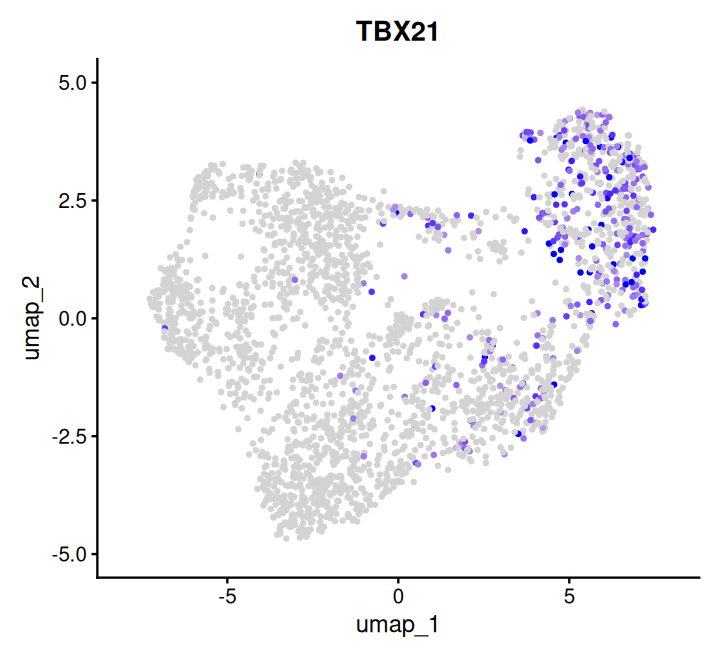

In [243]:
FeaturePlot(sample, features = c("TBX21"), max.cutoff = 1) + NoLegend()

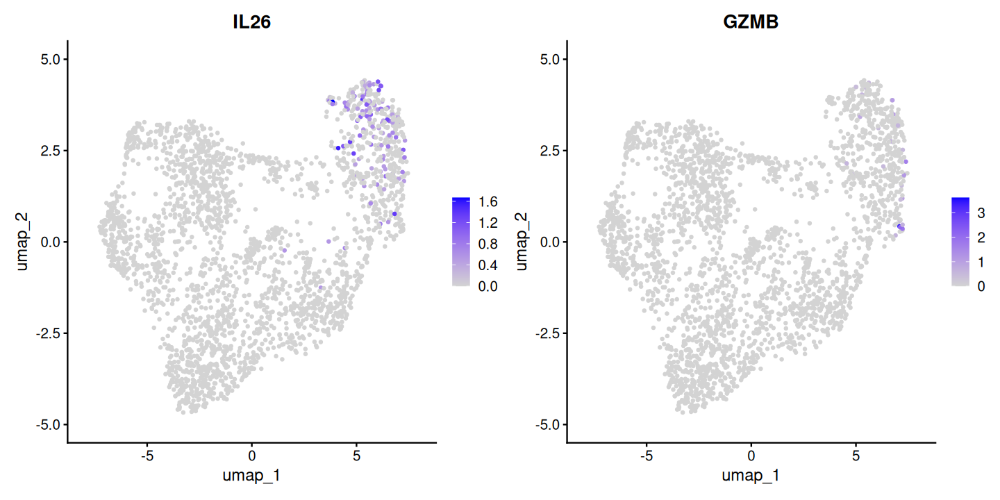

In [114]:
FeaturePlot(sample, features = c("IL26","GZMB"))

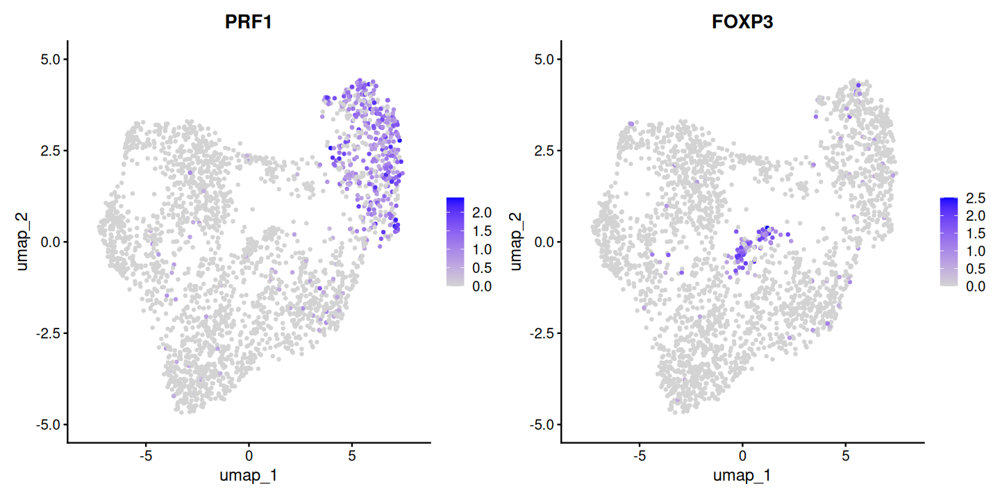

In [115]:
FeaturePlot(sample, features = c("PRF1","FOXP3"))

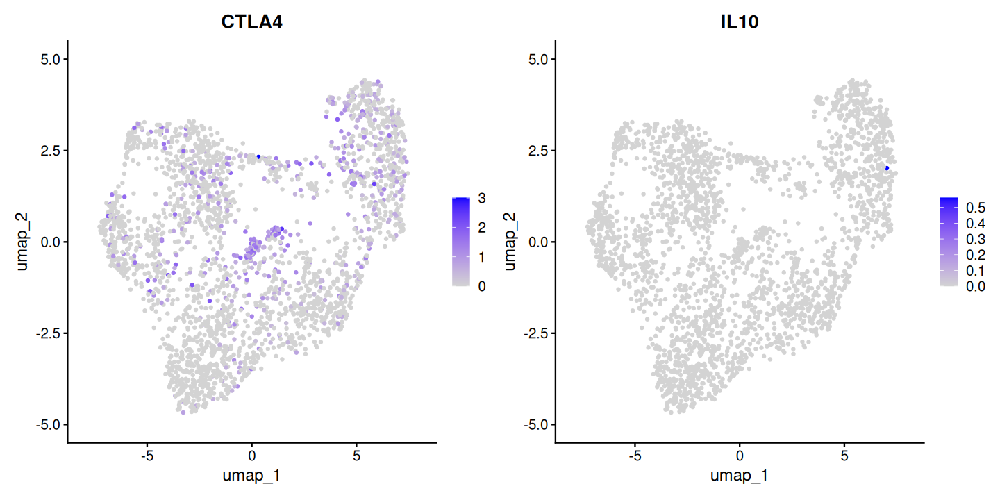

In [116]:
FeaturePlot(sample, features = c("CTLA4","IL10"))

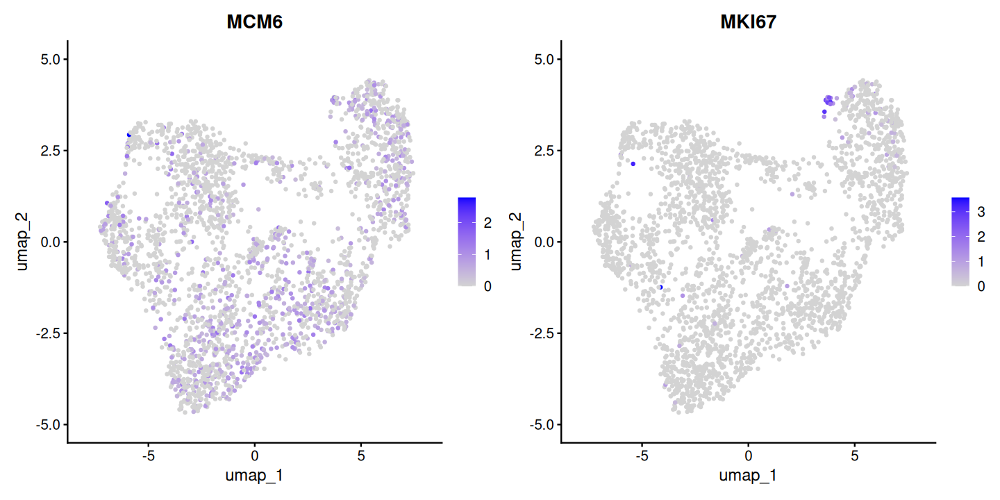

In [117]:
FeaturePlot(sample, features = c("MCM6","MKI67"))

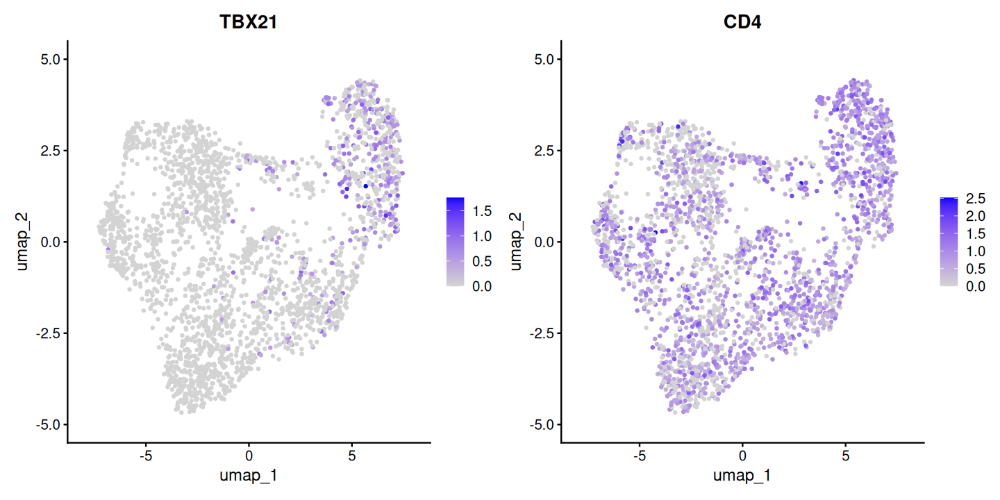

In [118]:
FeaturePlot(sample, features = c("TBX21","CD4"))

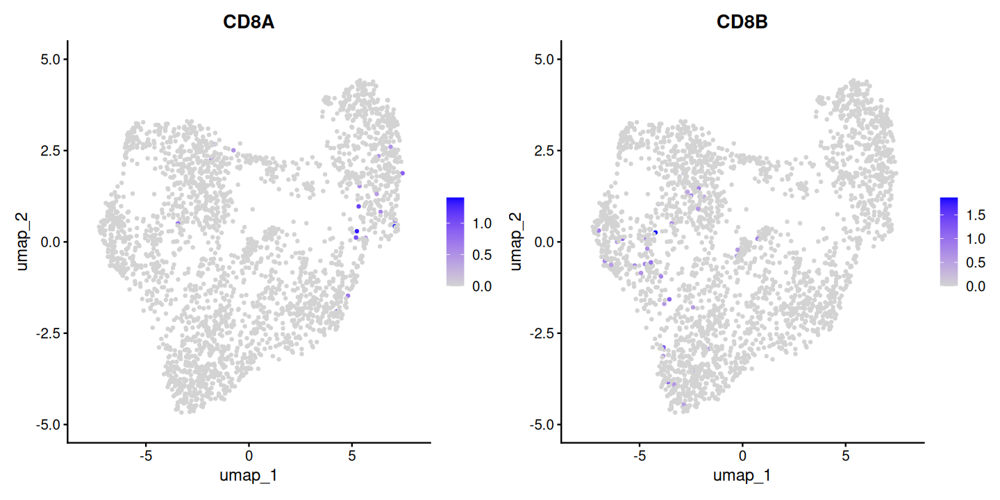

In [119]:
FeaturePlot(sample, features = c("CD8A","CD8B"))

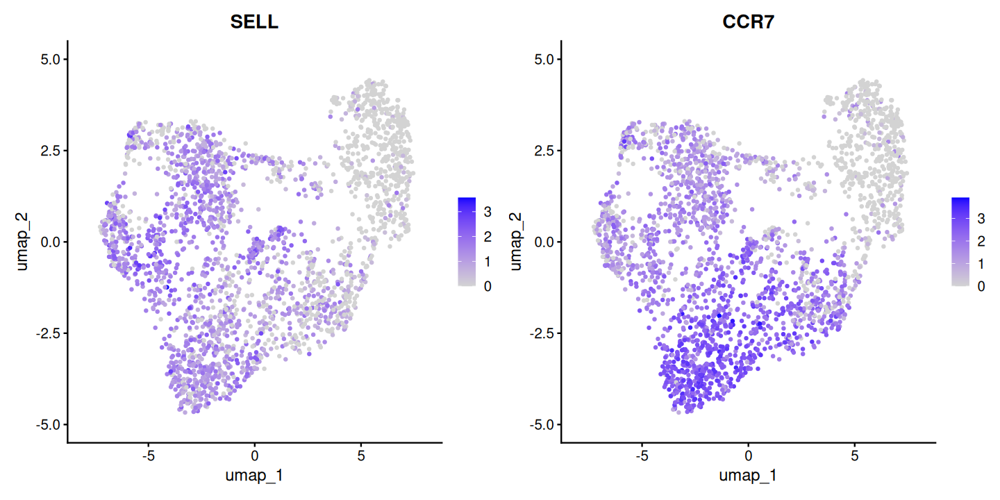

In [135]:
FeaturePlot(sample, features = c("SELL","CCR7"))

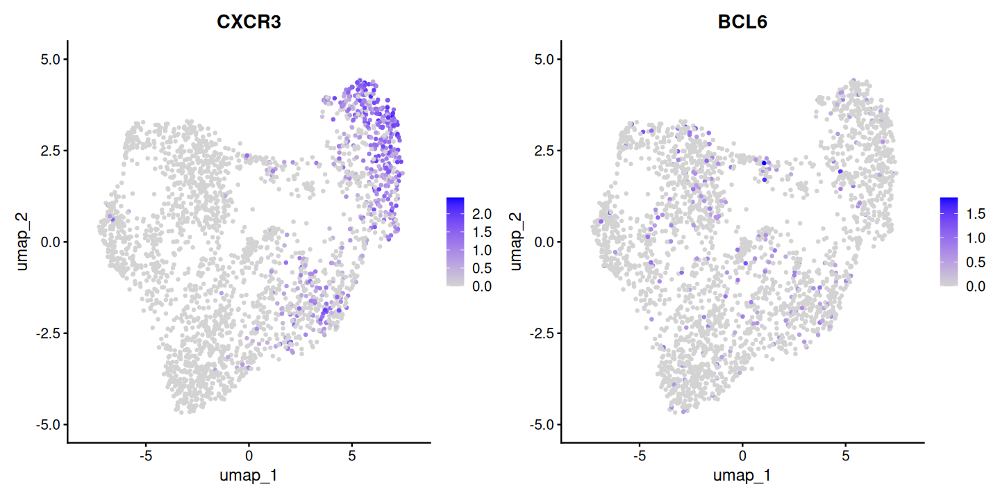

In [136]:
FeaturePlot(sample, features = c("CXCR3","BCL6"))

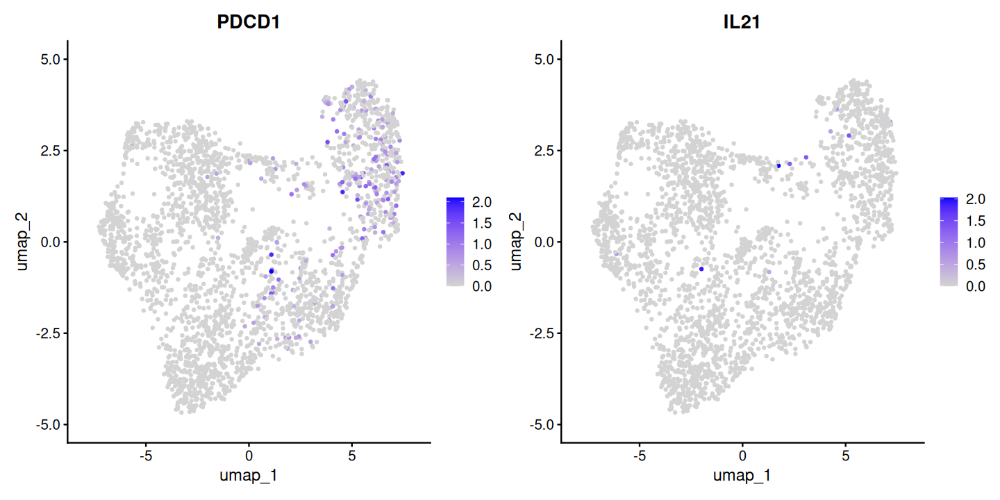

In [137]:
FeaturePlot(sample, features = c("PDCD1","IL21"))

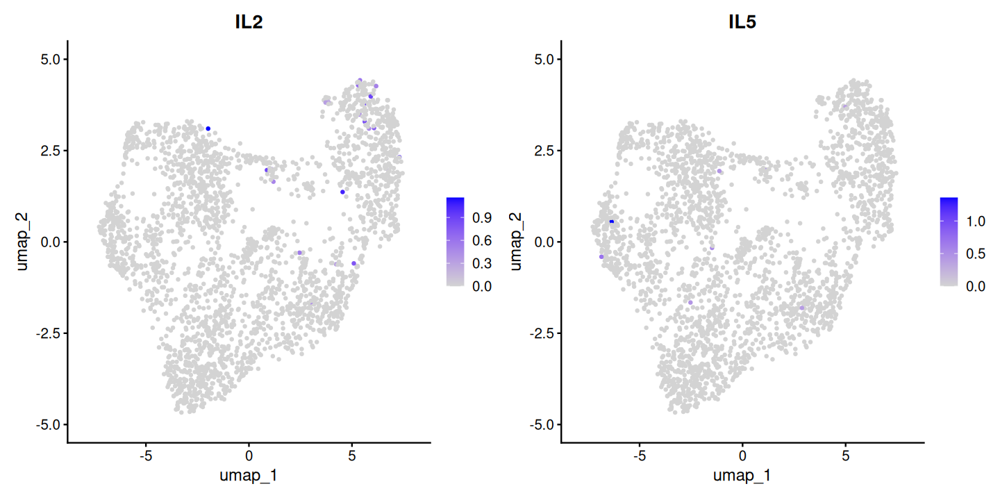

In [142]:
FeaturePlot(sample, features = c("IL2","IL5"))

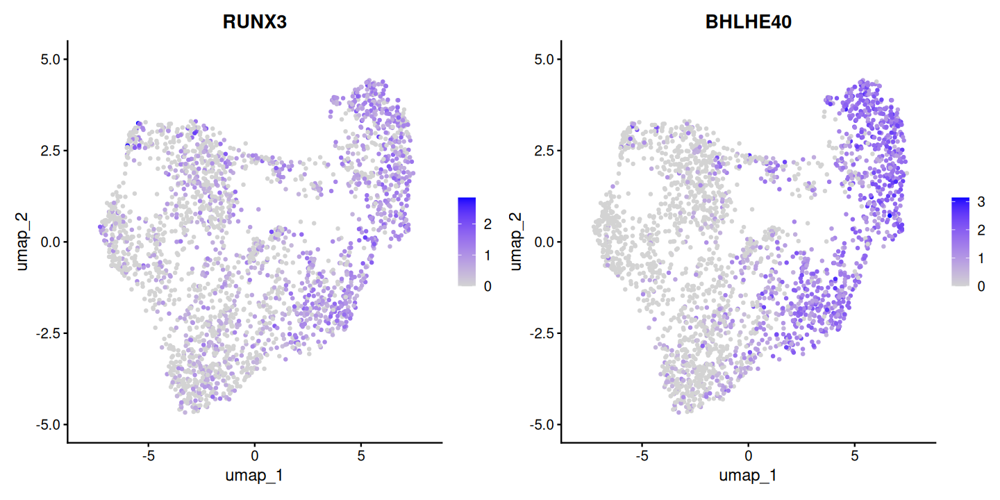

In [120]:
FeaturePlot(sample, features = c("RUNX3","BHLHE40"))

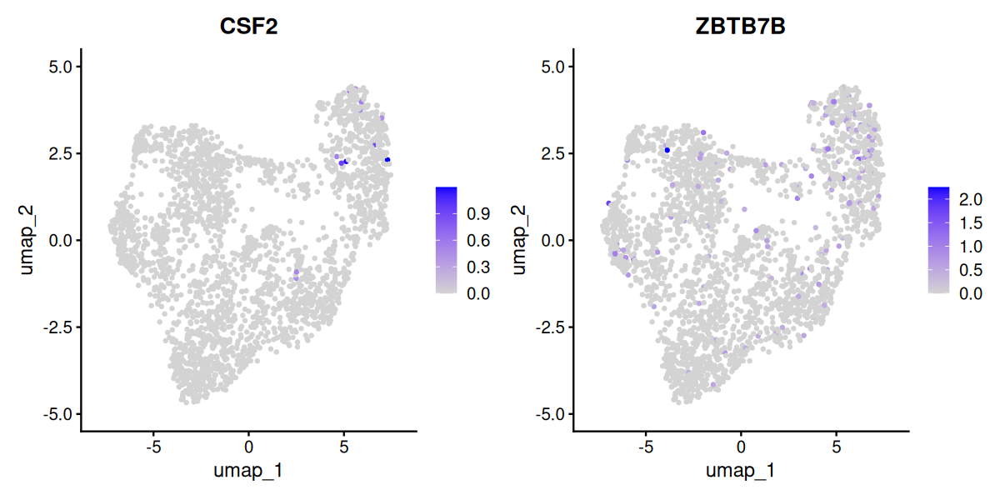

In [183]:
FeaturePlot(sample, features = c("CSF2","ZBTB7B"))

## DEG sample1 sample2

In [125]:
Idents(sample)  <- sample$sample

In [126]:
mrk  <- FindAllMarkers(sample, only.pos = T)

Calculating cluster Sample1

Calculating cluster Sample2



In [127]:
mrk  %>% dplyr::filter(cluster == "Sample2")

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
CST7,0.000000e+00,4.306671,0.900,0.085,0.000000e+00,Sample2,CST7
NKG7,0.000000e+00,4.860540,0.821,0.030,0.000000e+00,Sample2,NKG7
GZMA,0.000000e+00,5.163808,0.844,0.058,0.000000e+00,Sample2,GZMA
CXCR6,0.000000e+00,6.153663,0.746,0.017,0.000000e+00,Sample2,CXCR6
CEBPD,2.343847e-320,6.298486,0.716,0.021,4.593941e-316,Sample2,CEBPD
CCL5,8.605704e-297,4.412554,0.829,0.073,1.686718e-292,Sample2,CCL5
GNLY,4.109769e-294,5.476775,0.738,0.042,8.055146e-290,Sample2,GNLY
PRF1,1.296358e-279,4.782641,0.712,0.041,2.540862e-275,Sample2,PRF1
LINC01871,2.385948e-254,4.054162,0.808,0.101,4.676459e-250,Sample2,LINC01871


In [128]:
mrk  %>% dplyr::filter(cluster == "Sample2" & p_val_adj > 9.253668e-179)  

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
B2M,1.876794e-181,1.0546031,1.000,0.997,3.678517e-177,Sample2,B2M
IL18R1,3.877830e-179,3.0473604,0.757,0.148,7.600547e-175,Sample2,IL18R1
RUNX2,9.253668e-179,2.6638259,0.825,0.189,1.813719e-174,Sample2,RUNX2
SH3BGRL3,1.759365e-177,1.7890354,1.000,0.872,3.448355e-173,Sample2,SH3BGRL3
GYG1,9.704001e-176,3.2019785,0.738,0.152,1.901984e-171,Sample2,GYG1
HLA-DPB1,1.358152e-175,3.1414489,0.723,0.133,2.661977e-171,Sample2,HLA-DPB1
C12orf75,1.156695e-174,2.8759986,0.789,0.179,2.267122e-170,Sample2,C12orf75
CD74,1.579809e-173,2.4970976,0.983,0.703,3.096426e-169,Sample2,CD74
ALOX5AP,5.728209e-173,2.9624820,0.834,0.246,1.122729e-168,Sample2,ALOX5AP


In [129]:
mrk  %>% dplyr::filter(cluster == "Sample2" & p_val_adj > 9.253668e-143)  

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
ATP2B4,9.846279e-147,2.160994,0.910,0.405,1.929871e-142,Sample2,ATP2B4
BHLHE40,1.417758e-146,2.072982,0.930,0.369,2.778806e-142,Sample2,BHLHE40
CD52,6.114563e-143,1.575053,0.998,0.942,1.198454e-138,Sample2,CD52
ENSG00000227240,7.094934e-143,2.984829,0.586,0.089,1.390607e-138,Sample2,ENSG00000227240
CCR6,3.588246e-141,1.793110,0.825,0.196,7.032962e-137,Sample2,CCR6
HLA-DQB1,6.505664e-141,3.500805,0.510,0.060,1.275110e-136,Sample2,HLA-DQB1
RBPJ,1.126876e-138,2.099571,0.928,0.562,2.208676e-134,Sample2,RBPJ
EFHD2,1.013105e-135,2.095765,0.915,0.493,1.985686e-131,Sample2,EFHD2
GOLIM4,1.840967e-134,5.254674,0.333,0.010,3.608295e-130,Sample2,GOLIM4


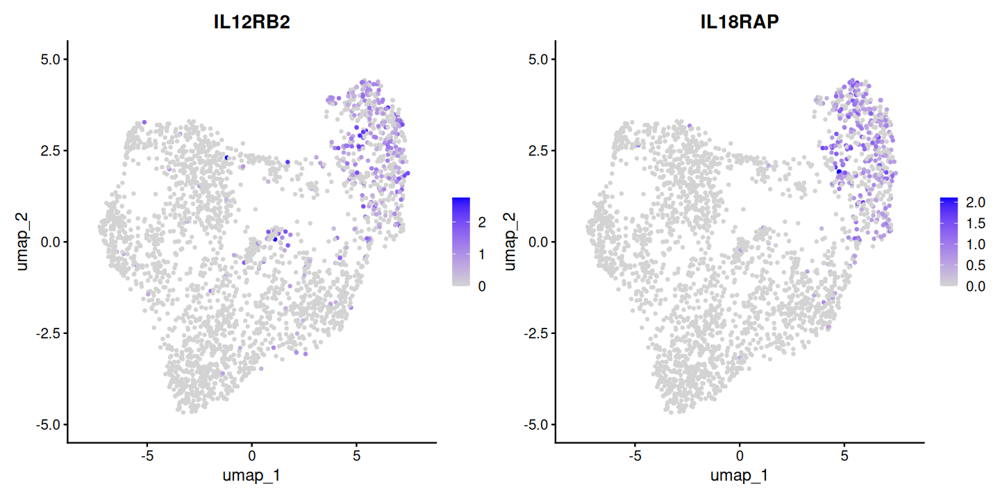

In [130]:
FeaturePlot(sample, features = c("IL12RB2","IL18RAP"))

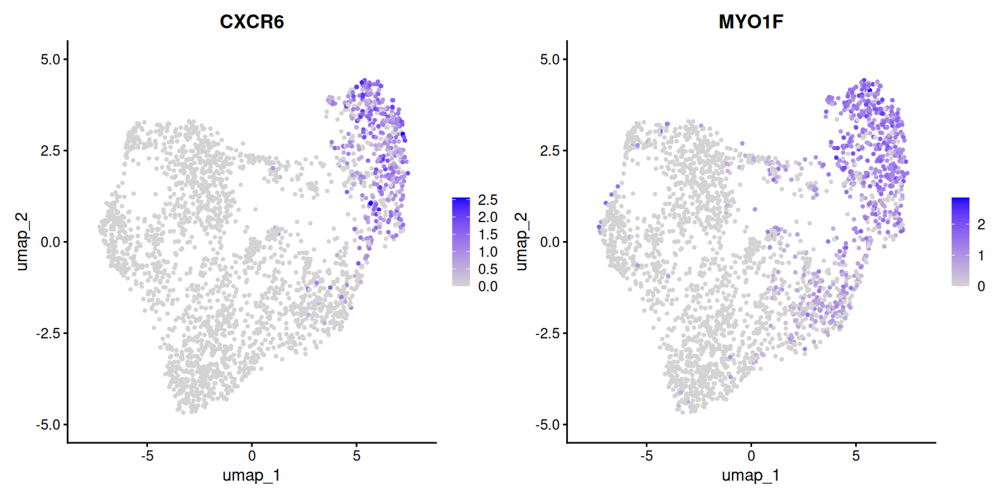

In [131]:
FeaturePlot(sample, features = c("CXCR6","MYO1F"))

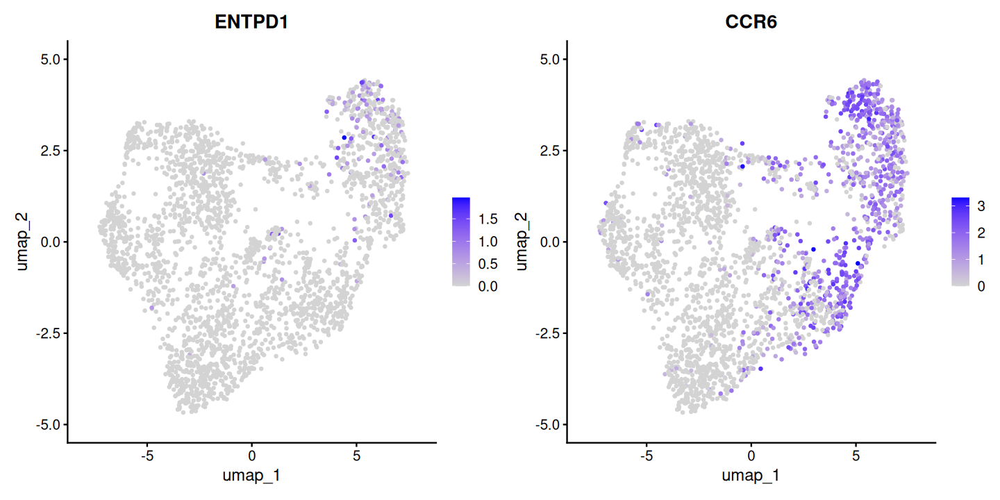

In [132]:
FeaturePlot(sample, features = c("ENTPD1","CCR6"))

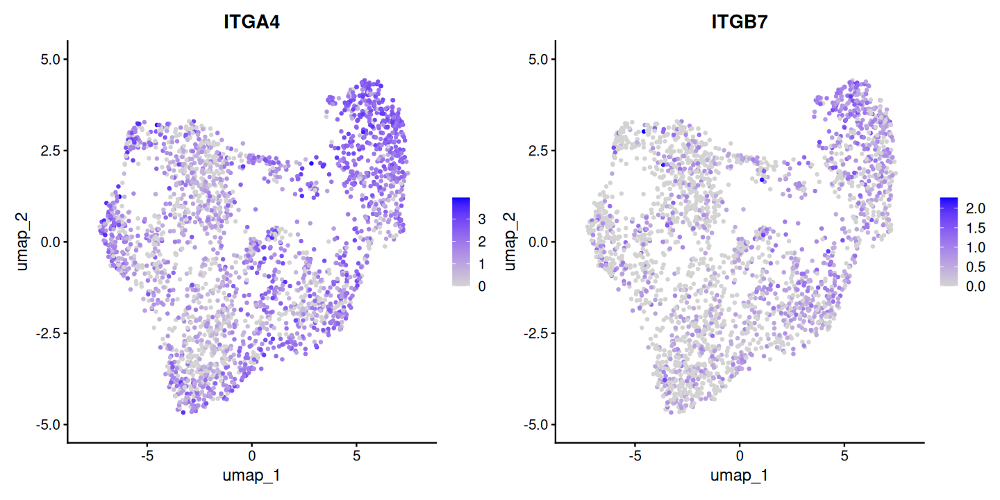

In [133]:
FeaturePlot(sample, features = c("ITGA4","ITGB7"))

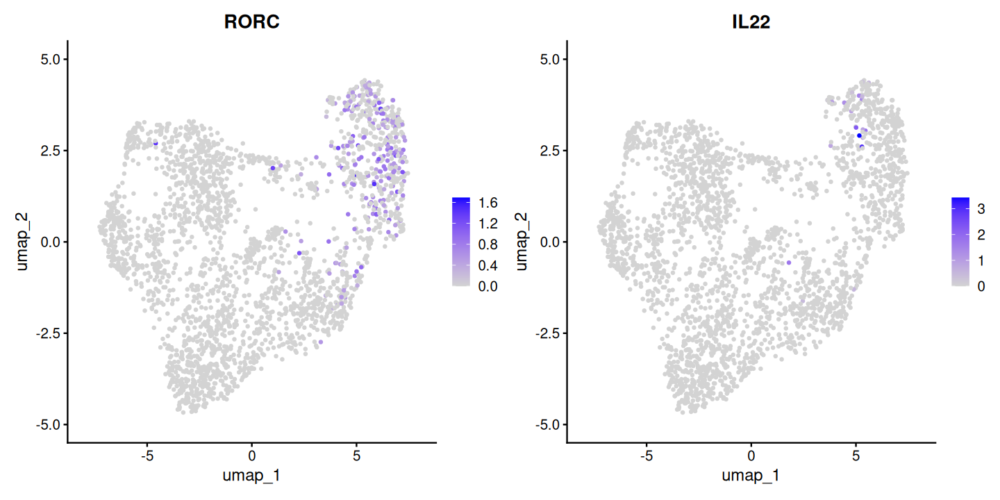

In [162]:
FeaturePlot(sample, features = c("RORC","IL22"))

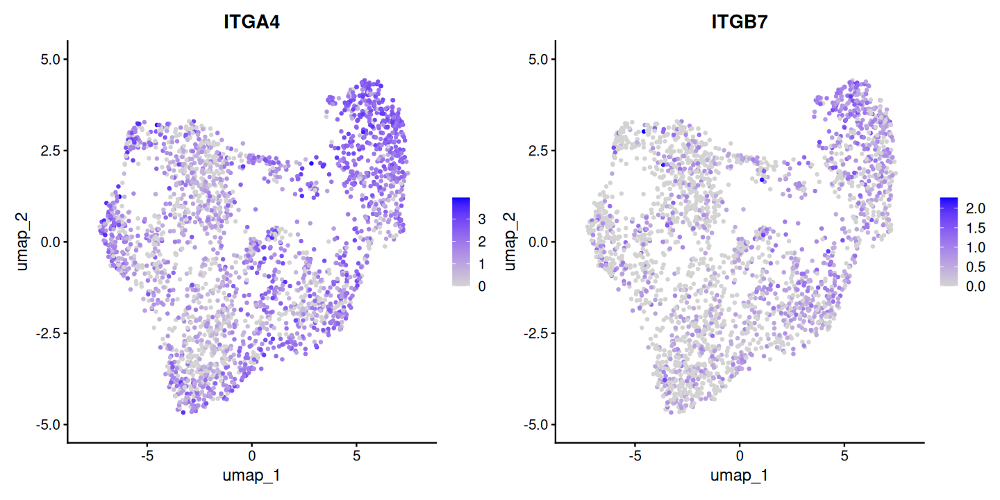

In [134]:
FeaturePlot(sample, features = c("ITGA4","ITGB7"))

# Aggregation per donor

In [147]:
sample@meta.data  %>% group_by(Freemuxlet_ID, sample, Freemuxlet_doublet)  %>% tally

Freemuxlet_ID,sample,Freemuxlet_doublet,n
<chr>,<chr>,<chr>,<int>
"0,0",Sample1,SNG,413
"0,0",Sample2,SNG,356
"1,0",Sample1,DBL,1
"1,1",Sample1,SNG,396
"1,1",Sample2,SNG,61
"2,2",Sample1,SNG,399
"2,2",Sample2,SNG,8
"3,0",Sample1,DBL,2
"3,1",Sample1,DBL,1


In [149]:
sample@meta.data   <- sample@meta.data  %>% mutate(Donor_ID = ifelse(Freemuxlet_doublet == "SNG",
                                              paste(sample, Freemuxlet_ID),
                                               "Doublet"
                                                    ))  

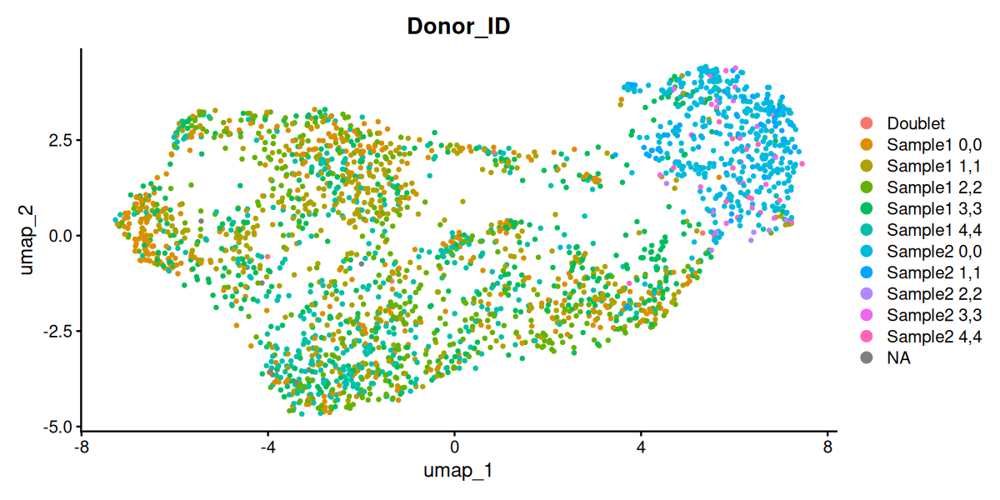

In [184]:
DimPlot(sample, group.by = "Donor_ID")

In [151]:
sample$keep  <- TRUE

In [152]:
sample@meta.data  <- sample@meta.data   %>% mutate(keep = ifelse(is.na(Freemuxlet_ID) | Donor_ID == "Doublet",FALSE,TRUE))

In [153]:
sample$keep  %>% table

.
FALSE  TRUE 
   13  2510 

In [154]:
sample_filt  <- subset(sample, keep == TRUE)

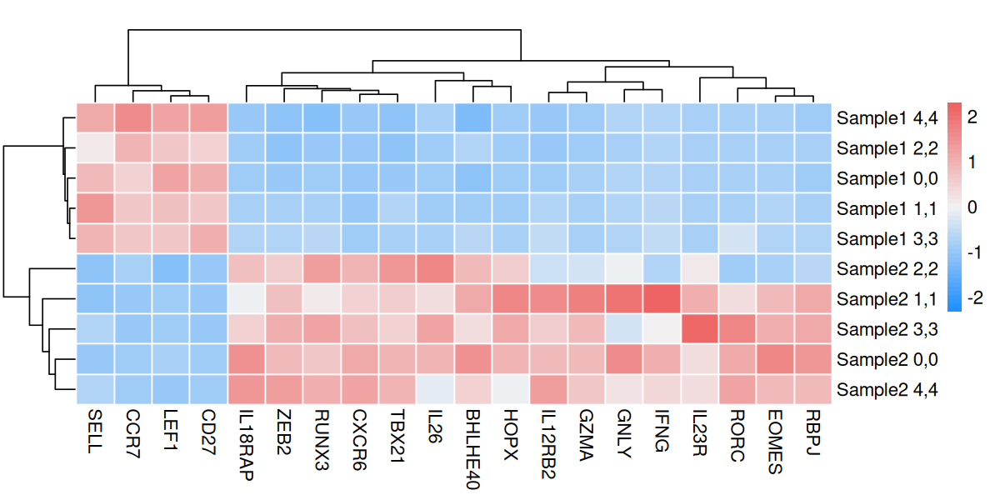

In [178]:
markers2  <- c("GNLY", "CXCR6", "CD27", "GZMA", 
              "IFNG", "TBX21", 
              "IL23R", "IL26",
               "IL12RB2","IL18RAP",
               "RBPJ","BHLHE40","RUNX3","ZEB2","RORC",
               "CCR7","SELL","EOMES","LEF1","HOPX"
               )

avgexp = AverageExpression(sample_filt, features = markers2, group.by = "Donor_ID",
                          assay = "RNA")

options(repr.plot.width = 10, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 13)

In [179]:
dir.create("figures/sorted_cd4_ctl/")

In [180]:
markers2  <- c("GNLY", "CXCR6", "CD27", "GZMA", 
              "IFNG", "TBX21", 
              "IL23R", "IL26",
               "IL12RB2","IL18RAP",
               "RBPJ","BHLHE40","RUNX3","ZEB2","RORC",
               "CCR7","SELL","EOMES","LEF1","HOPX"
               )

avgexp = AverageExpression(sample_filt, features = markers2, group.by = "Donor_ID",
                          assay = "RNA")

options(repr.plot.width = 10, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white", width = 10, height = 5,
                  fontsize = 13, filename = "figures/sorted_cd4_ctl/heatmap.pdf")

## DEG sample1 sample2 DESeq

In [167]:
aggexp_sample  <- AggregateExpression(sample_filt, group.by = c("Donor_ID", "sample"), return.seurat = T)

Centering and scaling data matrix



In [170]:
aggexp_sample  <- NormalizeData(aggexp_sample)
aggexp_sample  <- ScaleData(aggexp_sample)

Normalizing layer: counts

Centering and scaling data matrix



In [171]:
Idents(aggexp_sample)  <- aggexp_sample$sample

In [172]:
mrk_deseq  <- FindAllMarkers(aggexp_sample, test.use = "DESeq2", only.pos = T)

Calculating cluster Sample1

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

Calculating cluster Sample2

converting counts to integer mode

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



In [174]:
mrk_deseq  %>% dplyr::filter(cluster == "Sample2")

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
CCL5,2.447751e-59,4.1164502,1,1,4.797591e-55,Sample2,CCL5
GYG1,1.251132e-43,2.3314532,1,1,2.452219e-39,Sample2,GYG1
EFHD2,1.198725e-42,1.7880252,1,1,2.349501e-38,Sample2,EFHD2
NCR3,2.655510e-34,1.7896915,1,1,5.204800e-30,Sample2,NCR3
HOPX,4.169922e-34,2.3408568,1,1,8.173047e-30,Sample2,HOPX
GZMK,2.786756e-31,3.2651444,1,1,5.462043e-27,Sample2,GZMK
MGME1,6.989635e-31,1.5402483,1,1,1.369968e-26,Sample2,MGME1
ARPC5L,1.270976e-29,1.4323695,1,1,2.491112e-25,Sample2,ARPC5L
DPP4,8.781174e-29,1.5169735,1,1,1.721110e-24,Sample2,DPP4


# Mapping sorted cells on Blood 5p dataset

In [190]:
blood_5p  <- readRDS("data/5p_blood_2024/blood_5p_integrated_stacas_participant_filt_with_annot.rds")

In [191]:
blood_5p

An object of class Seurat 
19054 features across 593574 samples within 2 assays 
Active assay: integrated (1000 features, 1000 variable features)
 2 layers present: data, scale.data
 1 other assay present: RNA
 2 dimensional reductions calculated: pca, umap

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



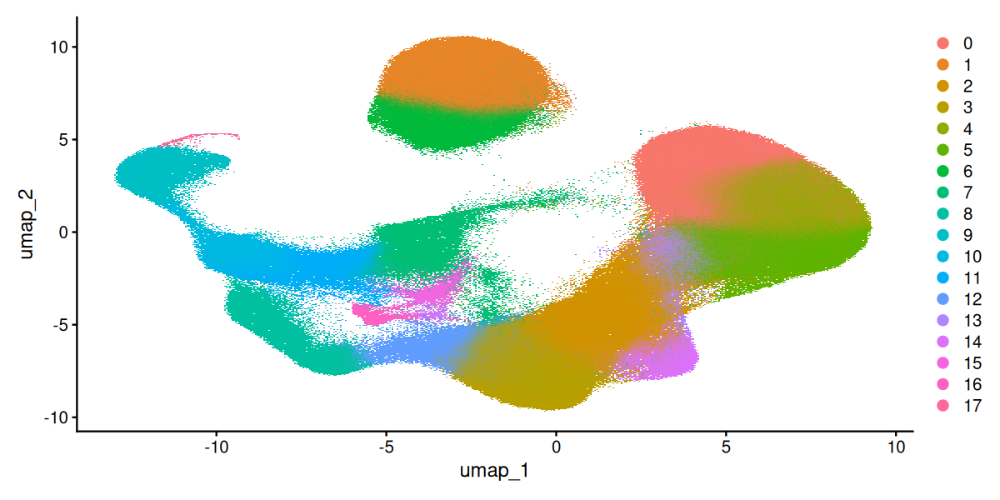

In [192]:
DimPlot(blood_5p)

In [195]:
blood_5p@commands$RunUMAP

Command: RunUMAP(blood_integrated, dims = 1:12)
Time: 2025-01-07 01:59:40.834183
dims : 1 2 3 4 5 6 7 8 9 10 11 12 
reduction : pca 
assay : integrated 
slot : data 
umap.method : uwot 
return.model : FALSE 
n.neighbors : 30 
n.components : 2 
metric : cosine 
learning.rate : 1 
min.dist : 0.3 
spread : 1 
set.op.mix.ratio : 1 
local.connectivity : 1 
repulsion.strength : 1 
negative.sample.rate : 5 
uwot.sgd : FALSE 
seed.use : 42 
angular.rp.forest : FALSE 
densmap : FALSE 
dens.lambda : 2 
dens.frac : 0.3 
dens.var.shift : 0.1 
verbose : TRUE 
reduction.name : umap 

In [198]:
blood_5p.ref <- RunUMAP(blood_5p, dims = 1:12, reduction = "pca", return.model = TRUE)

UMAP will return its model

20:46:37 UMAP embedding parameters a = 0.9922 b = 1.112

20:46:37 Read 593574 rows and found 12 numeric columns

20:46:37 Using Annoy for neighbor search, n_neighbors = 30

20:46:37 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

20:48:09 Writing NN index file to temp file /home/vercanie/R/tmp//RtmpbToa4I/file2a24ea54553e1b

20:48:10 Searching Annoy index using 1 thread, search_k = 3000

20:54:20 Annoy recall = 100%

20:54:23 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

20:55:18 Initializing from normalized Laplacian + noise (using RSpectra)

20:57:18 Commencing optimization for 200 epochs, with 25420110 positive edges

20:57:18 Using rng type: pcg

21:04:20 Optimization finished



Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



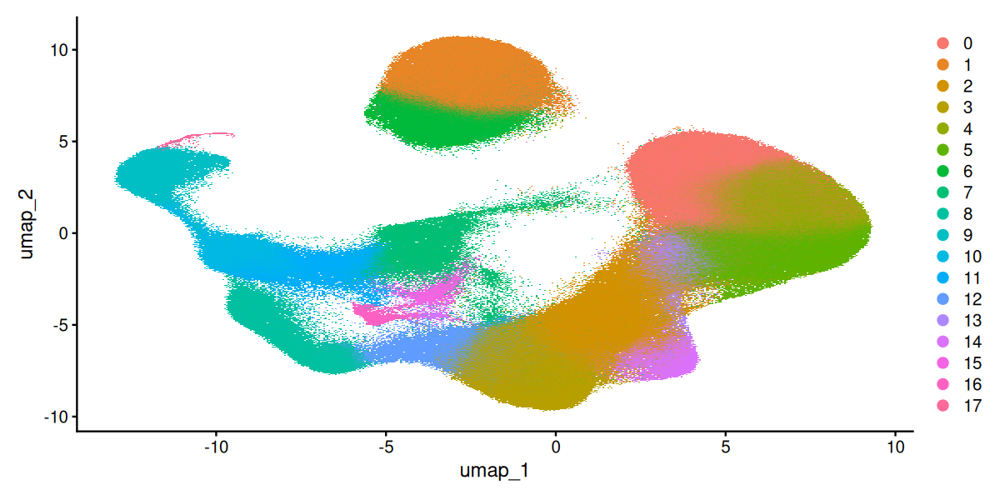

In [199]:
DimPlot(blood_5p.ref)

In [200]:
blood_5p.anchors <- FindTransferAnchors(reference = blood_5p.ref, query = sample2_filt,
    dims = 1:12, reference.reduction = "pca")

Projecting cell embeddings

Finding neighborhoods

Finding anchors

	Found 1124 anchors



In [201]:
ref <- MapQuery(anchorset = blood_5p.anchors, reference = blood_5p.ref, query = sample2_filt,
    refdata = blood_5p.ref$annotations, reference.reduction = "pca", reduction.model = "umap")

Finding integration vectors

Finding integration vector weights

Predicting cell labels

Warning message:
“Feature names cannot have underscores ('_'), replacing with dashes ('-')”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”

Integrating dataset 2 with reference dataset

Finding integration vectors

Integrating data

Computing nearest neighbors

Running UMAP projection

21:43:42 Read 469 rows

21:43:42 Processing block 1 of 1

21:43:42 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

21:43:42 Initializing by weighted average of neighbor coordinates using 1 thread

21:43:42 Commencing optimization for 67 epochs, with 14070 positive edges

21:43:43 Finished



In [ ]:
df <- as.data.frame(blood_5p.ref@reductions$umap@cell.embeddings)
df$source <- "reference"

df2 <- as.data.frame(ref@reductions$ref.umap@cell.embeddings)
df2$source <- "query"

colnames(df2) <- colnames(df)
df3 <- rbind(df, df2)

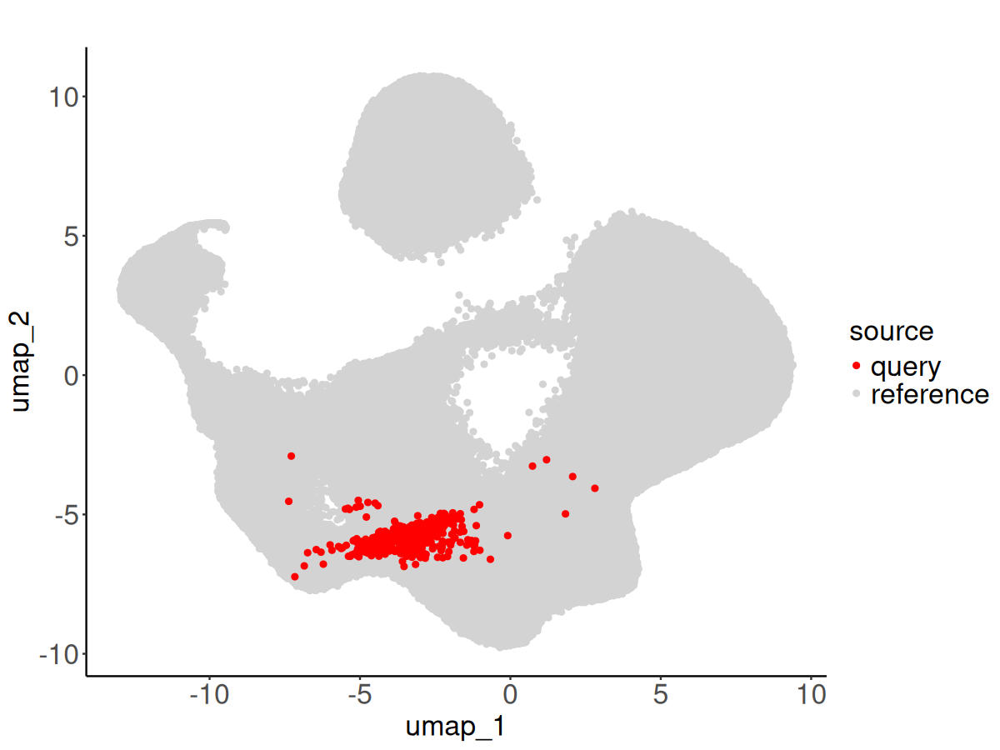

In [206]:
options(repr.plot.width = 10, repr.plot.height = 7.5)
df3 %>% ggplot() +
  geom_point(aes(x = umap_1, y = umap_2, color = source)) +
  scale_color_manual(values = c("red", "lightgrey")) + 
  theme_classic() + 
  ggtitle("") + ggtheme()

## Density plot

In [222]:
library(ggplot2)
library(dplyr)
library(viridis)

colfunc <- colorRampPalette(c("white","grey75","dodgerblue","green","yellow","red"))

In [209]:
df3

,umap_1,umap_2,source
,<dbl>,<dbl>,<chr>
AAACCTGAGAGATGAG-1_1_1_1,-0.7965160,7.9613457,reference
AAACCTGAGAGTACCG-1_1_1_1,-4.0378816,5.7994013,reference
AAACCTGAGAGTGAGA-1_1_1_1,1.1418684,-5.1547828,reference
AAACCTGAGCTGAACG-1_1_1_1,-2.9394613,5.6902518,reference
AAACCTGAGGCAATTA-1_1_1_1,2.8825702,1.9427443,reference
AAACCTGAGGCTAGAC-1_1_1_1,3.9046545,0.3203655,reference
AAACCTGAGTAGCCGA-1_1_1_1,-0.6217462,-7.7663870,reference
AAACCTGCAACTGCGC-1_1_1_1,5.2622094,-3.1871693,reference
AAACCTGCAACTTGAC-1_1_1_1,3.7069862,-3.4228299,reference


In [212]:
options(repr.plot.width = 10, repr.plot.height = 12)


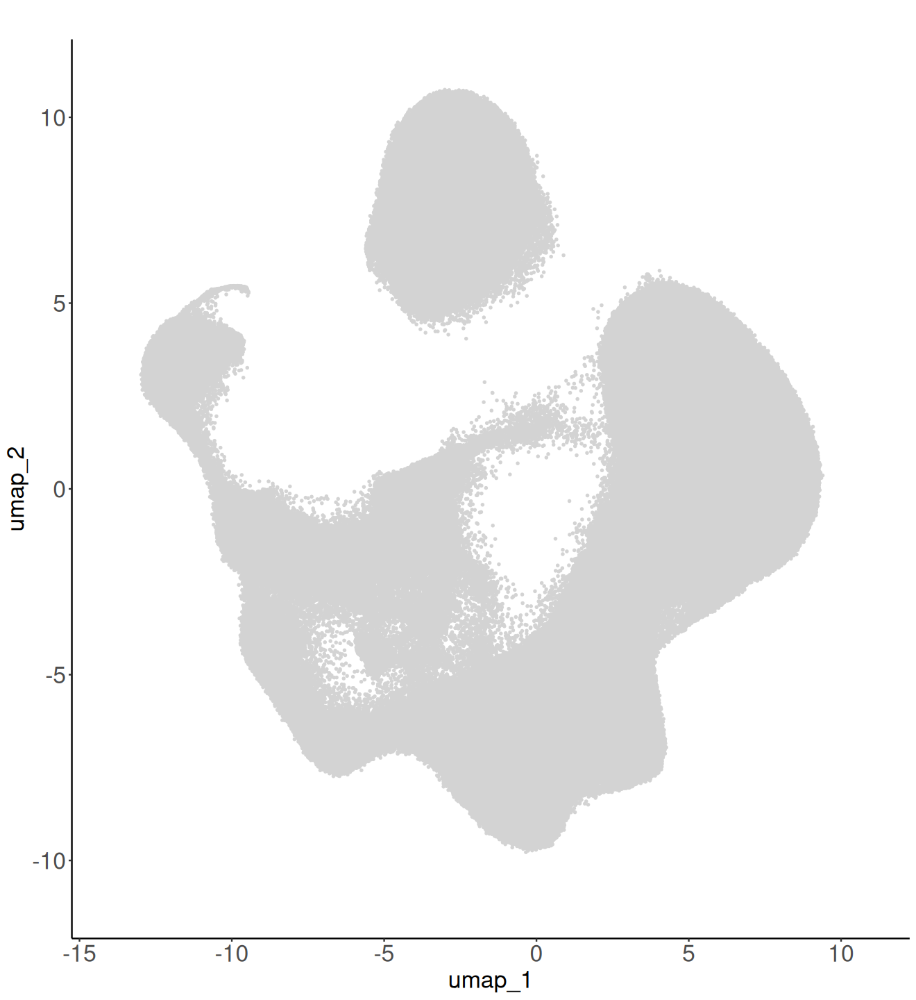

In [230]:
options(repr.plot.width = 11, repr.plot.height = 12)
df3 %>% ggplot() +
  geom_point(aes(x = umap_1, y = umap_2, color = source), size = 0.5) +
  scale_color_manual(values = c("lightgrey", "lightgrey")) + 
  theme_classic() + 
  ggtitle("") + ggtheme() +
xlim(-14,11)+  ylim(-11,11) + NoLegend()

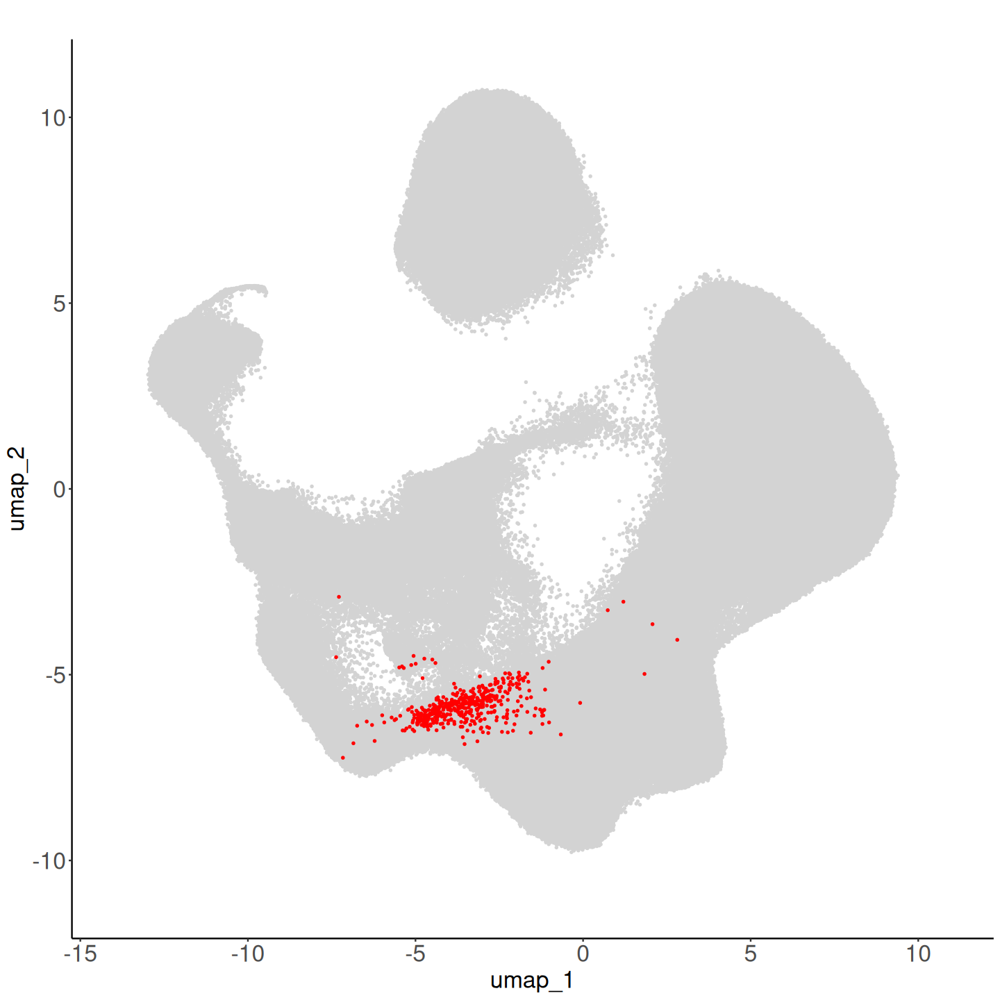

In [232]:
options(repr.plot.width = 12, repr.plot.height = 12)
df3 %>% ggplot() +
  geom_point(aes(x = umap_1, y = umap_2, color = source), size = 0.5) +
  scale_color_manual(values = c("red", "lightgrey")) + 
  theme_classic() + 
  ggtitle("") + ggtheme() +
xlim(-14,11)+  ylim(-11,11) + NoLegend()